# Notebook_D (dùng chung, phần mô hình, Sinh viên B): chia dữ liệu, sáu họ mô hình, tổng quát hoá, tin cậy, giải thích và chẩn đoán

**Dùng chung cho mọi đề tài.** Nhận `data/processed/feat.parquet` và `manifest.json` từ Notebook_C, đọc CONFIG như A, chạy tuần tự. Trả lời **RQ2** (mô hình nào tốt nhất theo tầm và có tổng quát hoá theo thời gian, theo đơn vị không) và **RQ3** (bao phủ khoảng tin cậy, cảnh báo sự kiện, đổi chế độ, đóng góp của nguồn phụ), rồi giải thích bằng SHAP và chẩn đoán.

**Sản phẩm**: `report/table_rq2_*.csv`, `report/table_rq3_*.csv`, `report/fig_rq2_*.png`, `report/fig_rq3_*.png`, `report/table_shap.csv`, `report/table_diagnosis.csv`, AI Audit Log cập nhật.

In [2]:
# ============================================================
# NOTEBOOK D - MODELING, GENERALIZATION AND RELIABILITY
# Group 4 - ADY201m
# ============================================================

TOPIC = (
    "Hourly Electric Vehicle Charging Demand Forecasting for Sustainable Cities "
    "from the City of Palo Alto Open Data with Unseen-station Transfer "
    "and Regime-shift Robustness"
)

GROUP = "Nhom 4"

PRIMARY_SOURCE = {
    "name": "City of Palo Alto EV Charging Station Usage (Open Data Portal)",
    "url": "https://data.paloalto.gov/",
    "license": "Open Data",
    "path": "data/raw/palo_alto_ev_charging.csv"
}

SECOND_SOURCE = {
    "name": "Open-Meteo Hourly Weather - Moffett Field Area",
    "url": "https://archive-api.open-meteo.com/",
    "license": "Open data",
    "path": "data/raw/secondary.csv"
}

EVENT_QUANTILE = 0.90
SEEDS = [0, 1, 2, 3, 4]

print("Topic:", TOPIC)
print("Group:", GROUP)

Topic: Hourly Electric Vehicle Charging Demand Forecasting for Sustainable Cities from the City of Palo Alto Open Data with Unseen-station Transfer and Regime-shift Robustness
Group: Nhom 4


In [2]:
# ============================================================
# AI AUDIT LOG HELPER
# ============================================================

import os
import datetime as dt
import pandas as pd

os.makedirs("report", exist_ok=True)

AUDIT_PATH = "report/ai_audit_log.csv"

def audit(
    step,
    prompt,
    tool,
    ai_output_summary,
    verified_how,
    decision,
    hallucination=False
):
    """
    Append one verified AI interaction to the audit log.
    """

    row = {
        "date": dt.date.today().isoformat(),
        "group": GROUP,
        "step": step,
        "prompt": prompt[:500],
        "tool": tool,
        "ai_output": ai_output_summary[:500],
        "verified_how": verified_how[:300],
        "decision": decision[:300],
        "hallucination": int(hallucination)
    }

    pd.DataFrame([row]).to_csv(
        AUDIT_PATH,
        mode="a",
        header=not os.path.exists(AUDIT_PATH),
        index=False
    )

    print("Audit entry saved:", step)

print("AI Audit Log ready:", AUDIT_PATH)

AI Audit Log ready: report/ai_audit_log.csv


## Hướng dẫn hỏi AI (điền đề tài của nhóm vào chỗ trống)

Quy tắc: hỏi **cụ thể** (kèm tên cột, kích thước, thông báo lỗi), yêu cầu AI **giải thích lý do** và **nêu cách kiểm tra**, rồi tự kiểm tra trước khi dùng. Mỗi prompt làm thay đổi bài phải ghi vào AI Audit Log bằng hàm `audit(...)` ở ô trên. Mẫu prompt theo bước (thay `{TOPIC}`, `{cột}` bằng thông tin thật của nhóm):

| Bước | Mẫu prompt | Cần tự kiểm tra gì |
|---|---|---|
| Mô hình | "Đề tài {TOPIC}, mục tiêu {TARGET_COL} tần suất {FREQ}, tầm {HORIZONS}. Với sáu họ mô hình (naive mùa, ridge, random forest, LightGBM toàn cục, tuyến tính dài hạn, mô hình nền zero-shot) hãy nêu siêu tham số nào đáng tinh chỉnh nhất và vì sao." | Chỉ tinh chỉnh khi chênh lệch giữa mô hình lớn hơn chênh lệch giữa seed |
| Thu thập | "Đề tài của tôi là {TOPIC}. Nguồn chính là {PRIMARY_SOURCE}. Hãy gợi ý 3 nguồn phụ công khai (thời tiết, sự kiện, giá, lịch) có thể ghép theo cột {TIME_COL} và {UNIT_COL}, kèm URL tải và giấy phép." | Mở URL, xác nhận có tải được và giấy phép cho phép dùng |
| So sánh nguồn | "Tôi có hai nguồn về cùng biến {TARGET_COL} ở tần suất {FREQ}. Hãy đề xuất 4 chỉ số để so sánh độ phủ, độ trễ cập nhật và độ lệch giữa hai nguồn." | Chạy lại số trên dữ liệu thật, không dùng số AI đưa |
| Làm sạch | "Cột {cột} có {x}% thiếu, thiếu theo cụm dài nhất {n} bước. Nên nội suy hay bỏ? Giải thích rủi ro rò rỉ tương lai." | Kiểm tra nội suy không dùng giá trị tương lai |
| SQL | "Viết truy vấn DuckDB tạo đặc trưng trễ {SEASON} bước và trung bình trượt theo {UNIT_COL}, có WINDOW, không rò rỉ." | Đếm dòng, kiểm tra cột NULL ở đầu chuỗi |
| EDA | "Từ bảng thống kê sau (dán bảng), nêu 3 nhận xét có thể kiểm chứng và 2 điều cần cảnh giác." | Mỗi nhận xét phải chỉ ra được ô số liệu tương ứng |
| Lỗi | "Lỗi: {dán nguyên văn}. Ngữ cảnh: {ô code}. Nguyên nhân và cách sửa tối thiểu?" | Sửa xong chạy lại ô test |

Ví dụ ghi Audit Log sau khi hỏi: `audit("Thu thập", "Đề tài ... gợi ý nguồn phụ", "Claude", "3 nguồn: NOAA ISD, ...", "mở 3 URL, 1 URL lỗi 404", "dùng NOAA ISD, loại nguồn 404", hallucination=True)`.

## Bước 0: nhận bàn giao và kiểm tra

**Làm gì**: đọc manifest, so mã MD5, nạp bảng đặc trưng vào DuckDB. **Vì sao**: nếu A sửa dữ liệu sau khi bàn giao mà B không biết, kết quả hai người sẽ không khớp; MD5 phát hiện ngay.

In [3]:
# ============================================================
# STEP 0 - IMPORTS, STYLE AND HANDOVER CHECK
# ============================================================

import os
import json
import hashlib
import time
import pickle
import warnings

import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)

# -------------------------
# Plot style
# -------------------------

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

TEAL = "#1B6B6D"
ACC = "#F4A261"
GREY = "#9FBFBF"

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(
        f"report/{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)
    print(f"Saved: report/{name}.png")


# -------------------------
# Handover paths
# -------------------------

MANIFEST_PATH = "data/processed/manifest.json"
FEAT_PATH = "data/processed/feat.parquet"

assert os.path.exists(MANIFEST_PATH), \
    "manifest.json not found."

assert os.path.exists(FEAT_PATH), \
    "feat.parquet not found."


# -------------------------
# Read manifest
# -------------------------

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    man = json.load(f)


# -------------------------
# MD5 verification
# -------------------------

with open(FEAT_PATH, "rb") as f:
    current_md5 = hashlib.md5(f.read()).hexdigest()

assert current_md5 == man["md5"], \
    "feat.parquet differs from manifest.json. Re-run the handover from Notebook C."


# -------------------------
# Configuration from C
# -------------------------

UNIT_COL = man["unit_col"]
TIME_COL = man["time_col"]
TARGET_COL = man["target_col"]

FREQ = man["freq"]
HORIZONS = man["horizons"]
SEASON = man["season"]
TEST_START = man["test_start"]

EXOG_COLS = man["exog_cols"]


# -------------------------
# Load feature table
# -------------------------

feat = pd.read_parquet(FEAT_PATH)

feat[TIME_COL] = pd.to_datetime(
    feat[TIME_COL],
    errors="coerce"
)

assert feat[TIME_COL].notna().all(), \
    "Invalid timestamps found in feat.parquet."

# Important: guarantee station-time order
feat = feat.sort_values(
    [UNIT_COL, TIME_COL]
).reset_index(drop=True)

assert not feat[[UNIT_COL, TIME_COL]].duplicated().any(), \
    "Duplicate station-time rows detected."


# -------------------------
# DuckDB registration
# -------------------------

con = duckdb.connect()
con.register("feat", feat)


# -------------------------
# Handover summary
# -------------------------

print("========== HANDOVER OK ==========")
print(f"Rows       : {len(feat):,}")
print(f"Units      : {feat[UNIT_COL].nunique()}")
print(f"Start      : {feat[TIME_COL].min()}")
print(f"End        : {feat[TIME_COL].max()}")
print(f"Unit col   : {UNIT_COL}")
print(f"Time col   : {TIME_COL}")
print(f"Target     : {TARGET_COL}")
print(f"Exogenous  : {EXOG_COLS}")
print(f"Frequency  : {FREQ}")
print(f"Horizons   : {HORIZONS}")
print(f"Season     : {SEASON}")
print(f"Test start : {TEST_START}")
print("MD5        : OK")
print("=================================")

========== HANDOVER OK ==========
Rows       : 602,872
Units      : 26
Start      : 2011-07-29 20:00:00
End        : 2020-12-31 17:00:00
Unit col   : station
Time col   : ts
Target     : kwh
Exogenous  : ['temp_c', 'precip_mm']
Frequency  : h
Horizons   : [1, 24]
Season     : 24
Test start : 2020-01-01
MD5        : OK


In [8]:
# ===== PATCH 1: phong cách hình thống nhất =====
# Quy tắc màu: xám = phần phụ, teal = phần chính, cam = chỉ 1 điểm cần nhìn
TEAL = "#1B6B6D"
GREY = "#B5C0C0"
DARK = "#3A4A4A"
ACC  = "#F4A261"

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)

def legend_out(ax, ncol=4):
    # chú thích nằm NGOÀI vùng biểu đồ, góc trên bên trái
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=ncol,
              frameon=False, fontsize=8, borderaxespad=0)

def callout(ax, x, y, text, dx=0, dy=0):
    # ghi số/nhãn trực tiếp lên điểm quan trọng
    ax.annotate(text, xy=(x, y), xytext=(x + dx, y + dy),
                fontsize=8, fontweight="bold", color=DARK,
                arrowprops=dict(arrowstyle="-", color=DARK, lw=0.8))

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(f"report/{name}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: report/{name}.png")

print("Style patch OK")

Style patch OK


## Bước 4: chia dữ liệu và mốc naive

**Ba cách chia, mỗi cách trả lời một câu hỏi**: (1) **theo thời gian** (huấn luyện trước `TEST_START`, kiểm thử sau) trả lời "mô hình có dùng được cho tương lai không"; (2) **lùi gốc dự báo** (rolling origin, nhiều điểm cắt) trả lời "kết quả có ổn định theo thời gian không"; (3) **để dành đơn vị** (leave-units-out) trả lời "mô hình có dùng cho trạm, vùng, khách hàng mới không".

**Mốc naive** là điều kiện tối thiểu: mô hình nào không thắng mốc naive thì không đáng báo cáo. Hai mốc: persistence (giá trị hiện tại) và naive mùa (giá trị cách đúng một mùa).

In [4]:
# ============================================================
# STEP 4A - FEATURE LIST AND USABLE MODELING DATA
# ============================================================

# Primary forecast horizon
H0 = HORIZONS[0]
Y = f"y_h{H0}"

# Lag / rolling features created in Notebook C
lag_cols = [
    c for c in feat.columns
    if (
        c.startswith("y_lag")
        or c.startswith("y_ma")
        or c.startswith("y_sd")
        or c == "y_diff1"
    )
]

# Current weather variables
exog_now = [
    c for c in EXOG_COLS
    if c in feat.columns
]

# Lagged weather variables
exog_lag = [
    c for c in feat.columns
    if c.endswith("_lag_season")
]

# Calendar variables
cal_cols = [
    c for c in ["hr", "dow", "mon", "doy"]
    if c in feat.columns
]

# Encode station ID for global models
feat["unit_code"] = (
    feat[UNIT_COL]
    .astype("category")
    .cat.codes
)

# Complete feature list
X_cols = (
    [TARGET_COL]
    + lag_cols
    + exog_now
    + exog_lag
    + cal_cols
    + ["unit_code"]
)

# Remove duplicates while preserving order
X_cols = list(dict.fromkeys(X_cols))

# Required forecast targets
target_cols = [
    f"y_h{h}"
    for h in HORIZONS
]

# Safety checks
missing_targets = [
    c for c in target_cols
    if c not in feat.columns
]

assert not missing_targets, \
    f"Missing forecast target columns: {missing_targets}"

assert len(lag_cols) > 0, \
    "No lag features found."

# Remove rows where lag features or future targets are unavailable
data = (
    feat
    .dropna(subset=lag_cols + target_cols)
    .sort_values([TIME_COL, UNIT_COL])
    .reset_index(drop=True)
    .copy()
)

# Final checks
assert len(data) > 0, \
    "No usable rows remain after dropping missing lags/targets."

assert data[X_cols].notna().all().all(), \
    "Some model features still contain missing values."


print("========== MODEL DATA ==========")
print("Primary horizon :", H0)
print("Primary target  :", Y)
print("Lag features    :", lag_cols)
print("Weather now     :", exog_now)
print("Weather lagged  :", exog_lag)
print("Calendar        :", cal_cols)
print("Feature count   :", len(X_cols))
print(f"Rows usable     : {len(data):,} of {len(feat):,}")
print("Units           :", data[UNIT_COL].nunique())
print("================================")

========== MODEL DATA ==========
Primary horizon : 1
Primary target  : y_h1
Lag features    : ['y_lag1', 'y_lag2', 'y_lag3', 'y_lag24', 'y_lag48', 'y_lag168', 'y_ma_season', 'y_sd_season', 'y_diff1']
Weather now     : ['temp_c', 'precip_mm']
Weather lagged  : ['temp_c_lag_season', 'precip_mm_lag_season']
Calendar        : ['hr', 'dow', 'mon', 'doy']
Feature count   : 19
Rows usable     : 597,880 of 602,872
Units           : 26


In [5]:
# ============================================================
# STEP 4B - CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================================

split_time = pd.Timestamp(TEST_START)

train = (
    data[data[TIME_COL] < split_time]
    .copy()
)

test = (
    data[data[TIME_COL] >= split_time]
    .copy()
)

# Primary-horizon matrices
X_tr = train[X_cols]
y_tr = train[Y]

X_te = test[X_cols]
y_te = test[Y]

# -------------------------
# Safety checks
# -------------------------

assert len(train) > 0, "Training set is empty."
assert len(test) > 0, "Test set is empty."

assert train[TIME_COL].max() < test[TIME_COL].min(), \
    "Temporal leakage detected: train and test overlap."

assert X_tr.notna().all().all(), \
    "Training features contain NaN."

assert X_te.notna().all().all(), \
    "Test features contain NaN."

assert y_tr.notna().all(), \
    "Training target contains NaN."

assert y_te.notna().all(), \
    "Test target contains NaN."


# -------------------------
# Summary
# -------------------------

total = len(train) + len(test)

print("========== TIME SPLIT ==========")

print("Split date :", split_time)

print(
    f"Train      : {len(train):,} rows "
    f"({len(train) / total:.1%})"
)

print(
    "Train time :",
    train[TIME_COL].min(),
    "->",
    train[TIME_COL].max()
)

print(
    f"Test       : {len(test):,} rows "
    f"({len(test) / total:.1%})"
)

print(
    "Test time  :",
    test[TIME_COL].min(),
    "->",
    test[TIME_COL].max()
)

print(
    "Train units:",
    train[UNIT_COL].nunique()
)

print(
    "Test units :",
    test[UNIT_COL].nunique()
)

print("Temporal overlap: NONE")
print("================================")

========== TIME SPLIT ==========
Split date : 2020-01-01 00:00:00
Train      : 548,799 rows (91.8%)
Train time : 2011-08-18 12:00:00 -> 2019-12-31 23:00:00
Test       : 49,081 rows (8.2%)
Test time  : 2020-01-01 00:00:00 -> 2020-12-29 10:00:00
Train units: 26
Test units : 26
Temporal overlap: NONE


In [6]:
# ============================================================
# STEP 4C - NAIVE BASELINES FOR ALL FORECAST HORIZONS
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

def naive_predictions(frame, h):
    """
    Persistence:
        predict future demand using current demand.

    Seasonal naive:
        predict using demand from one daily season (24 hours) ago.
    """

    persistence = frame[TARGET_COL].to_numpy()

    seasonal_col = f"y_lag{SEASON}"

    if seasonal_col in frame.columns:
        seasonal = frame[seasonal_col].to_numpy()
    else:
        seasonal = persistence.copy()

    return persistence, seasonal


baseline_rows = []

for h in HORIZONS:

    target_h = f"y_h{h}"

    y_true = test[target_h].to_numpy()

    persistence, seasonal = naive_predictions(
        test,
        h
    )

    # Persistence metrics
    pers_mae = mean_absolute_error(
        y_true,
        persistence
    )

    pers_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            persistence
        )
    )

    # Seasonal-naive metrics
    seas_mae = mean_absolute_error(
        y_true,
        seasonal
    )

    seas_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            seasonal
        )
    )

    baseline_rows.extend([
        {
            "horizon": h,
            "model": "Persistence",
            "MAE": pers_mae,
            "RMSE": pers_rmse
        },
        {
            "horizon": h,
            "model": "Seasonal Naive",
            "MAE": seas_mae,
            "RMSE": seas_rmse
        }
    ])


baseline_df = pd.DataFrame(baseline_rows)

baseline_df.to_csv(
    "report/table_baselines.csv",
    index=False
)


print("========== NAIVE BASELINES ==========")

for h in HORIZONS:

    temp = baseline_df[
        baseline_df["horizon"] == h
    ]

    print(f"\nHorizon h={h}")

    for _, row in temp.iterrows():

        print(
            f"{row['model']:<15} "
            f"MAE = {row['MAE']:.4f} | "
            f"RMSE = {row['RMSE']:.4f}"
        )

print("\nSaved: report/table_baselines.csv")
print("=====================================")

========== NAIVE BASELINES ==========

Horizon h=1
Persistence     MAE = 2.7329 | RMSE = 5.4612
Seasonal Naive  MAE = 8.1421 | RMSE = 11.6994

Horizon h=24
Persistence     MAE = 8.1293 | RMSE = 11.6975
Seasonal Naive  MAE = 8.1002 | RMSE = 11.6514

Saved: report/table_baselines.csv


## Chỉ số đánh giá và cách đọc

| Chỉ số | Công thức ngắn | Khi nào dùng | Cạm bẫy |
|---|---|---|---|
| MAE | trung bình \|y - ŷ\| | mọi bài, dễ hiểu, cùng đơn vị với mục tiêu | không phạt nặng sai số lớn |
| RMSE | căn trung bình (y - ŷ)² | khi sai số lớn tốn kém hơn | bị chi phối bởi ngoại lai |
| MAPE | trung bình \|y - ŷ\| / \|y\| | so sánh giữa đơn vị có quy mô khác nhau | nổ khi y gần 0; không dùng cho biến có số 0 |
| sMAPE | 2\|y - ŷ\| / (\|y\| + \|ŷ\|) | thay MAPE khi y có thể bằng 0 | không đối xứng thật sự |
| MASE | MAE / MAE của naive trong tập huấn luyện | so sánh giữa đề tài, giữa tầm; dưới 1 là thắng naive | cần naive cùng mùa |
| Pinball, coverage | phạt phân vị; tỷ lệ y nằm trong khoảng | dự báo xác suất và khoảng tin cậy | bao phủ đúng nhưng khoảng quá rộng là vô dụng, luôn báo cả độ rộng |

Trong bài: bảng chính báo MAE và MASE (kèm độ lệch chuẩn qua seed); bảng phụ báo RMSE, sMAPE; RQ3 báo coverage và độ rộng.

In [14]:
import os
print(os.getcwd())
print(os.path.exists("report"), os.listdir("report") if os.path.exists("report") else None)

c:\Users\TUF\OneDrive\A FPT\Semester 3\ADY201m\Week2_Notebooks_C_D_Sample_FA26
True ['ai_audit_log.csv', 'data_sources.csv', 'eda_note.md', 'eda_notes.md', 'fig_eda_acf.png', 'fig_eda_covariate_precip_mm.png', 'fig_eda_covariate_temp_c.png', 'fig_eda_crosscorr.png', 'fig_eda_distribution.png', 'fig_eda_missing.png', 'fig_eda_regime.png', 'fig_eda_seasonality.png', 'fig_eda_timeseries.png', 'fig_eda_units.png', 'fig_exercise_stl.png', 'fig_rq1_sql.png', 'profile.html', 'table_baselines.csv', 'table_cleaning_log.csv', 'table_covariate_corr.csv', 'table_describe.csv', 'table_per_unit.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_rq1_tests.csv', 'table_source_comparison.csv']


In [7]:
# ============================================================
# STEP 5A - METRICS HELPER
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

def smape(y_true, y_pred):
    """
    Symmetric Mean Absolute Percentage Error (%).
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    denominator = (
        np.abs(y_true)
        + np.abs(y_pred)
        + 1e-9
    )

    return float(
        np.mean(
            2.0 * np.abs(y_true - y_pred)
            / denominator
        ) * 100
    )


def get_mase_scale(h):
    """
    Calculate the in-sample seasonal-naive MAE
    from the training set for horizon h.
    """

    target_col = f"y_h{h}"

    y_train = train[target_col].to_numpy()

    _, seasonal_train = naive_predictions(
        train,
        h
    )

    scale = mean_absolute_error(
        y_train,
        seasonal_train
    )

    return max(float(scale), 1e-9)


def metrics(y_true, y_pred, h):
    """
    Return the main forecasting metrics.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "sMAPE": smape(y_true, y_pred),
        "MASE": float(
            mae / get_mase_scale(h)
        )
    }


# ============================================================
# QUICK CHECK USING SEASONAL-NAIVE BASELINE
# ============================================================

seasonal_pred = naive_predictions(
    test,
    H0
)[1]

metric_check = metrics(
    test[f"y_h{H0}"].to_numpy(),
    seasonal_pred,
    H0
)

print("========== METRICS CHECK ==========")

for name, value in metric_check.items():
    print(f"{name:<7}: {value:.4f}")

print("===================================")

========== METRICS CHECK ==========
MAE    : 8.1421
RMSE   : 11.6994
sMAPE  : 74.9993
MASE   : 1.3441


## Bước 6a: sáu họ mô hình, năm seed, mọi tầm dự báo

**Họ mô hình và lý do chọn**: naive mùa (điều kiện tối thiểu); ridge với trễ (tuyến tính, nhanh, khó overfit); random forest (phi tuyến, ít siêu tham số); LightGBM toàn cục (mạnh nhất cho bảng đặc trưng, học chung nhiều đơn vị); tuyến tính dài hạn (LTSF-Linear: một lớp tuyến tính từ cửa sổ trễ, mốc mạnh của các bài mô hình nền); mô hình nền zero-shot (Chronos, TimesFM: không huấn luyện, dự báo từ ngữ cảnh, đại diện cho xu hướng 2024-2025).

**Năm seed**: mô hình có ngẫu nhiên (random forest, LightGBM) chạy 5 lần; báo trung bình và độ lệch chuẩn. Nếu chênh lệch giữa hai mô hình nhỏ hơn hai lần độ lệch chuẩn thì không kết luận mô hình nào hơn.

In [20]:
# ============================================================
# STEP 6A-1 - MODEL ZOO
# Direct forecasting: one model per horizon
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor


def make_models(seed=42):

    return {

        # Fast linear baseline using all available features
        "Ridge": Ridge(
            alpha=1.0
        ),

        # Non-linear tree ensemble
        # Reduced size for ~550k training rows
        "RandomForest": RandomForestRegressor(
            n_estimators=120,
            max_depth=18,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=seed
        ),

        # Main global boosting model
        "LightGBM_global": LGBMRegressor(
            objective="regression",
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=0.1,
            n_jobs=-1,
            random_state=seed,
            verbosity=-1
        ),

        # Lightweight linear long-term forecasting baseline
        "LTSF_Linear": Ridge(
            alpha=0.1
        )
    }


# LTSF-Linear uses only the current target + lag history
LTSF_COLS = [
    TARGET_COL
] + [
    c for c in lag_cols
    if c.startswith("y_lag")
]

LTSF_COLS = list(dict.fromkeys(LTSF_COLS))


# -------------------------
# Check model configuration
# -------------------------

models_check = make_models(seed=42)

print("========== MODEL ZOO ==========")

for name, model in models_check.items():
    print(f"{name:<18}: {model.__class__.__name__}")

print("\nLTSF features:", LTSF_COLS)
print("Number of full features:", len(X_cols))
print("Number of LTSF features:", len(LTSF_COLS))

print("================================")


========== MODEL ZOO ==========
Ridge             : Ridge
RandomForest      : RandomForestRegressor
LightGBM_global   : LGBMRegressor
LTSF_Linear       : Ridge

LTSF features: ['kwh', 'y_lag1', 'y_lag2', 'y_lag3', 'y_lag24', 'y_lag48', 'y_lag168']
Number of full features: 19
Number of LTSF features: 7


In [21]:
# ============================================================
# STEP 6A-2 - RUN MODELS × SEEDS × HORIZONS
# Optimized for the current dataset
# ============================================================

import time

results = []
preds = {}

DETERMINISTIC_MODELS = {
    "Ridge",
    "LTSF_Linear"
}

STOCHASTIC_MODELS = {
    "RandomForest",
    "LightGBM_global"
}

print("========== RQ2 MODEL COMPARISON ==========")

for h in HORIZONS:

    print(f"\n========== HORIZON h={h} ==========")

    target_h = f"y_h{h}"

    ytr = train[target_h].to_numpy()
    yte = test[target_h].to_numpy()

    # --------------------------------------------------------
    # 1. NAIVE BASELINES
    # --------------------------------------------------------

    pers, seas = naive_predictions(test, h)

    for name, pred in [
        ("Persistence", pers),
        ("SeasonalNaive", seas)
    ]:

        m = metrics(
            yte,
            pred,
            h
        )

        results.append({
            "model": name,
            "h": h,
            "seed": 0,
            **m
        })

        if h == H0:
            preds[name] = pred

        print(
            f"{name:<18} "
            f"MAE={m['MAE']:.4f} | "
            f"RMSE={m['RMSE']:.4f}"
        )


    # --------------------------------------------------------
    # 2. DETERMINISTIC MODELS
    # Ridge and LTSF only need one run
    # --------------------------------------------------------

    deterministic = make_models(seed=42)

    for name in ["Ridge", "LTSF_Linear"]:

        model = deterministic[name]

        cols = (
            LTSF_COLS
            if name == "LTSF_Linear"
            else X_cols
        )

        print(f"\nTraining {name} | h={h} ...")

        start = time.time()

        model.fit(
            train[cols],
            ytr
        )

        pred = model.predict(
            test[cols]
        )

        elapsed = time.time() - start

        m = metrics(
            yte,
            pred,
            h
        )

        results.append({
            "model": name,
            "h": h,
            "seed": 42,
            "runtime_sec": elapsed,
            **m
        })

        if h == H0:
            preds[name] = pred

        print(
            f"{name:<18} "
            f"MAE={m['MAE']:.4f} | "
            f"RMSE={m['RMSE']:.4f} | "
            f"time={elapsed:.1f}s"
        )


    # --------------------------------------------------------
    # 3. STOCHASTIC MODELS
    # Run all five seeds
    # --------------------------------------------------------

    for seed in SEEDS:

        models = make_models(seed)

        for name in [
            "RandomForest",
            "LightGBM_global"
        ]:

            model = models[name]

            print(
                f"\nTraining {name} | "
                f"h={h} | seed={seed} ..."
            )

            start = time.time()

            model.fit(
                train[X_cols],
                ytr
            )

            pred = model.predict(
                test[X_cols]
            )

            elapsed = time.time() - start

            m = metrics(
                yte,
                pred,
                h
            )

            results.append({
                "model": name,
                "h": h,
                "seed": seed,
                "runtime_sec": elapsed,
                **m
            })

            # Keep seed 0 predictions for later plots
            if h == H0 and seed == 0:
                preds[name] = pred

            print(
                f"{name:<18} "
                f"seed={seed} | "
                f"MAE={m['MAE']:.4f} | "
                f"RMSE={m['RMSE']:.4f} | "
                f"time={elapsed:.1f}s"
            )


# ============================================================
# SAVE RAW RESULTS
# ============================================================

res = pd.DataFrame(results)

res.to_csv(
    "report/table_rq2_raw.csv",
    index=False
)


# ============================================================
# SUMMARY
# ============================================================

summary = (
    res
    .groupby(["model", "h"])[
        ["MAE", "RMSE", "sMAPE", "MASE"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\n\n========== RQ2 SUMMARY ==========")
display(summary)

print("\nSaved: report/table_rq2_raw.csv")
print("=================================")

========== RQ2 MODEL COMPARISON ==========

========== HORIZON h=1 ==========
Persistence        MAE=2.7329 | RMSE=5.4612
SeasonalNaive      MAE=8.1421 | RMSE=11.6994

Training Ridge | h=1 ...
Ridge              MAE=2.9237 | RMSE=5.0432 | time=0.3s

Training LTSF_Linear | h=1 ...
LTSF_Linear        MAE=2.9224 | RMSE=5.0653 | time=0.1s

Training RandomForest | h=1 | seed=0 ...
RandomForest       seed=0 | MAE=2.3000 | RMSE=4.3366 | time=52.2s

Training LightGBM_global | h=1 | seed=0 ...
LightGBM_global    seed=0 | MAE=2.3470 | RMSE=4.3863 | time=11.7s

Training RandomForest | h=1 | seed=1 ...
RandomForest       seed=1 | MAE=2.2988 | RMSE=4.3384 | time=46.2s

Training LightGBM_global | h=1 | seed=1 ...
LightGBM_global    seed=1 | MAE=2.3538 | RMSE=4.3973 | time=10.4s

Training RandomForest | h=1 | seed=2 ...
RandomForest       seed=2 | MAE=2.3179 | RMSE=4.3524 | time=54.1s

Training LightGBM_global | h=1 | seed=2 ...
LightGBM_global    seed=2 | MAE=2.3447 | RMSE=4.3840 | time=11.4s

Train

MAE             RMSE            sMAPE            MASE  \
                      mean     std     mean     std     mean     std    mean   
model           h                                                              
LTSF_Linear     1   2.9224     NaN   5.0653     NaN  33.7124     NaN  0.4824   
                24  5.8305     NaN   8.5079     NaN  58.5313     NaN  0.9641   
LightGBM_global 1   2.3487  0.0041   4.3881  0.0062  27.2220  0.0491  0.3877   
                24  5.7562  0.0012   8.4595  0.0018  57.7828  0.0108  0.9518   
Persistence     1   2.7329     NaN   5.4612     NaN  29.2700     NaN  0.4511   
                24  8.1293     NaN  11.6975     NaN  74.8330     NaN  1.3442   
RandomForest    1   2.3050  0.0076   4.3405  0.0067  27.0494  0.0783  0.3805   
                24  5.7865  0.0015   8.4497  0.0033  58.0803  0.0091  0.9568   
Ridge           1   2.9237     NaN   5.0432     NaN  33.8319     NaN  0.4826   
                24  5.8005     NaN   8.4428     NaN  58.2488     NaN  0.9592   
SeasonalNaive   1   8.1421     NaN  11.6994     NaN  74.9993     NaN  1.3441   
                24  8.1002     NaN  11.6514     NaN  74.8583     NaN  1.3394   

                            
                       std  
model           h           
LTSF_Linear     1      NaN  
                24     NaN  
LightGBM_global 1   0.0007  
                24  0.0002  
Persistence     1      NaN  
                24     NaN  
RandomForest    1   0.0013  
                24  0.0003  
Ridge           1      NaN  
                24     NaN  
SeasonalNaive   1      NaN  
                24     NaN


Saved: report/table_rq2_raw.csv


In [34]:
# ===== PATCH 2: LSTM làm mô hình đối chiếu =====
import time, os
import torch, torch.nn as nn

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))

if "res" not in dir():
    res = pd.read_csv("report/table_rq2_raw.csv")
if "preds" not in dir():
    preds = {}

SEQ_COLS = [c for c in ["y_lag168", "y_lag48", "y_lag24",
                        "y_lag3", "y_lag2", "y_lag1", TARGET_COL]
            if c in X_cols]
STAT_COLS = [c for c in X_cols if c not in SEQ_COLS and c != "unit_code"]
N_UNITS = int(data["unit_code"].max()) + 1
print("Sequence:", SEQ_COLS)
print("Static  :", STAT_COLS)

class EVLSTM(nn.Module):
    def __init__(self, n_static, n_units, hid=32):
        super().__init__()
        self.lstm = nn.LSTM(1, hid, batch_first=True)
        self.emb = nn.Embedding(n_units, 4)
        self.head = nn.Sequential(
            nn.Linear(hid + n_static + 4, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, seq, stat, u):
        _, (h, _) = self.lstm(seq)
        z = torch.cat([h[-1], stat, self.emb(u)], dim=1)
        return self.head(z).squeeze(1)

def fit_predict_lstm(tr_df, te_df, target, seed,
                     n_rows=200_000, epochs=8, bs=1024):
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    tr_df = tr_df.dropna(subset=SEQ_COLS + STAT_COLS + [target])
    if len(tr_df) > n_rows:
        tr_df = tr_df.iloc[rng.choice(len(tr_df), n_rows, replace=False)]

    # chuẩn hoá: chỉ fit trên train
    s_mu = tr_df[SEQ_COLS].values.mean()
    s_sd = tr_df[SEQ_COLS].values.std() + 1e-9
    st_mu = tr_df[STAT_COLS].mean().values
    st_sd = tr_df[STAT_COLS].std().values + 1e-9
    y_mu, y_sd = tr_df[target].mean(), tr_df[target].std() + 1e-9

    def prep(df):
        seq = torch.tensor((df[SEQ_COLS].values - s_mu) / s_sd,
                           dtype=torch.float32).unsqueeze(-1)
        stat = torch.tensor((df[STAT_COLS].values - st_mu) / st_sd,
                            dtype=torch.float32)
        u = torch.tensor(df["unit_code"].values, dtype=torch.long)
        return seq, stat, u

    seq, stat, u = prep(tr_df)
    y = torch.tensor(((tr_df[target].values - y_mu) / y_sd),
                     dtype=torch.float32)

    model = EVLSTM(len(STAT_COLS), N_UNITS)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    loss_fn = nn.L1Loss()          # khớp với metric MAE

    model.train()
    for ep in range(epochs):
        perm = torch.randperm(len(y))
        for i in range(0, len(y), bs):
            b = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(seq[b], stat[b], u[b]), y[b])
            loss.backward()
            opt.step()

    model.eval()
    seq_t, stat_t, u_t = prep(te_df)
    out = []
    with torch.no_grad():
        for i in range(0, len(seq_t), 8192):
            out.append(model(seq_t[i:i+8192], stat_t[i:i+8192],
                             u_t[i:i+8192]).numpy())
    pred = np.concatenate(out) * y_sd + y_mu
    return np.clip(pred, 0, None)

# ---- chạy: mọi horizon × 5 seed ----
rows = []
for h in HORIZONS:
    target = f"y_h{h}"
    for seed in SEEDS:
        t0 = time.time()
        p = fit_predict_lstm(train, test, target, seed)
        el = time.time() - t0
        m = metrics(test[target].to_numpy(), p, h)
        rows.append({"model": "LSTM", "h": h, "seed": seed,
                     "runtime_sec": el, **m})
        if h == H0 and seed == 0:
            preds["LSTM"] = p
        print(f"LSTM h={h} seed={seed} | MAE={m['MAE']:.4f} | "
              f"RMSE={m['RMSE']:.4f} | MASE={m['MASE']:.4f} | {el:.0f}s")

res = pd.concat([res[res["model"] != "LSTM"], pd.DataFrame(rows)],
                ignore_index=True)
res.to_csv("report/table_rq2_raw.csv", index=False)

cmp = (res[(res.h == H0) & res.model.isin(["RandomForest", "LightGBM_global", "LSTM"])]
       .groupby("model")[["MAE", "RMSE", "MASE"]].agg(["mean", "std"]).round(4))
display(cmp)

Sequence: ['y_lag168', 'y_lag48', 'y_lag24', 'y_lag3', 'y_lag2', 'y_lag1', 'kwh']
Static  : ['y_ma_season', 'y_sd_season', 'y_diff1', 'temp_c', 'precip_mm', 'temp_c_lag_season', 'precip_mm_lag_season', 'hr', 'dow', 'mon', 'doy']
LSTM h=1 seed=0 | MAE=2.2594 | RMSE=4.6883 | MASE=0.3730 | 16s
LSTM h=1 seed=1 | MAE=2.2817 | RMSE=4.7667 | MASE=0.3767 | 16s
LSTM h=1 seed=2 | MAE=2.2650 | RMSE=4.7071 | MASE=0.3739 | 16s
LSTM h=1 seed=3 | MAE=2.2405 | RMSE=4.6478 | MASE=0.3698 | 18s
LSTM h=1 seed=4 | MAE=2.2620 | RMSE=4.6925 | MASE=0.3734 | 18s
LSTM h=24 seed=0 | MAE=5.6542 | RMSE=8.6971 | MASE=0.9350 | 16s
LSTM h=24 seed=1 | MAE=5.6644 | RMSE=8.7658 | MASE=0.9366 | 18s
LSTM h=24 seed=2 | MAE=5.6605 | RMSE=8.7865 | MASE=0.9360 | 19s
LSTM h=24 seed=3 | MAE=5.6679 | RMSE=8.7313 | MASE=0.9372 | 19s
LSTM h=24 seed=4 | MAE=5.6692 | RMSE=8.7277 | MASE=0.9375 | 16s


MAE            RMSE            MASE        
                   mean     std    mean     std    mean     std
model                                                          
LSTM             2.2617  0.0147  4.7005  0.0431  0.3734  0.0024
LightGBM_global  2.3487  0.0041  4.3881  0.0062  0.3877  0.0007
RandomForest     2.3050  0.0076  4.3405  0.0067  0.3805  0.0013

In [35]:
# ===== PATCH 4 (bản A): Hình 2 - cột 1 giờ =====
MAIN_MODELS = ["Persistence", "SeasonalNaive", "Ridge",
               "LTSF_Linear", "RandomForest", "LightGBM_global", "LSTM"]
main = (res[(res["h"] == H0) & (res["model"].isin(MAIN_MODELS))]
        .groupby("model")["MAE"].mean().sort_values())

def pick_color(m):
    if m == "RandomForest": return TEAL   # mô hình chính (được tuning)
    if m == "LSTM":         return ACC    # mô hình đối chiếu
    return GREY

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(main.index, main.values, color=[pick_color(m) for m in main.index])
ax.bar_label(bars, fmt="%.3f", fontweight="bold", fontsize=9, padding=2)
ax.set_ylabel(f"MAE (kWh), horizon h={H0}")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

rf, ls = main["RandomForest"], main["LSTM"]
ax.text(0.99, 0.95,
        f"LSTM (untuned): {ls:.3f}  |  Random Forest: {rf:.3f}\n"
        f"Gap = {(1 - ls / rf) * 100:.1f}% of Random Forest MAE",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=8, fontweight="bold", color=DARK)
style(ax)
savefig(fig, "fig_rq2_model_comparison")
print(main.round(4))

Saved: report/fig_rq2_model_comparison.png
model
LSTM               2.2617
RandomForest       2.3050
LightGBM_global    2.3487
Persistence        2.7329
LTSF_Linear        2.9224
Ridge              2.9237
SeasonalNaive      8.1421
Name: MAE, dtype: float64


In [25]:
t3 = (res[res["model"].isin(["RandomForest", "LightGBM_global", "Persistence",
                              "LTSF_Linear", "Ridge", "SeasonalNaive", "LSTM"])]
      .pivot_table(index="model", columns="h", values=["MAE", "RMSE", "MASE"], aggfunc="mean")
      .round(4))
display(t3)

MAE            MASE             RMSE         
h                    1       24      1       24       1        24
model                                                            
LSTM             2.2617  5.6632  0.3734  0.9365   4.7005   8.7417
LTSF_Linear      2.9224  5.8305  0.4824  0.9641   5.0653   8.5079
LightGBM_global  2.3487  5.7562  0.3877  0.9518   4.3881   8.4595
Persistence      2.7329  8.1293  0.4511  1.3442   5.4612  11.6975
RandomForest     2.3050  5.7865  0.3805  0.9568   4.3405   8.4497
Ridge            2.9237  5.8005  0.4826  0.9592   5.0432   8.4428
SeasonalNaive    8.1421  8.1002  1.3441  1.3394  11.6994  11.6514

In [36]:
# ============================================================
# STEP 6A-3 - ZERO-SHOT FOUNDATION MODEL: CHRONOS
# ============================================================

fm_rows = []

try:
    from chronos import ChronosPipeline
    import torch

    print("Loading Chronos T5 Small...")

    pipe = ChronosPipeline.from_pretrained(
        "amazon/chronos-t5-small",
        device_map="cpu"
    )

    CTX = min(512, 8 * SEASON)
    n_units = min(20, test[UNIT_COL].nunique())

    yt_all = []
    yp_all = []

    print("Chronos loaded.")
    print("Context length:", CTX)
    print("Units evaluated:", n_units)
    print("Starting zero-shot evaluation...")

    for i, u in enumerate(test[UNIT_COL].unique()[:n_units], start=1):

        hist = (
            data[
                (data[UNIT_COL] == u)
                & (data[TIME_COL] < pd.Timestamp(TEST_START))
            ]
            .sort_values(TIME_COL)[TARGET_COL]
            .dropna()
            .values[-CTX:]
        )

        fut = (
            test[test[UNIT_COL] == u]
            .sort_values(TIME_COL)[TARGET_COL]
            .dropna()
            .values
        )

        if len(hist) == 0 or len(fut) < H0:
            continue

        ctx = list(hist)
        k = 0

        while k + H0 <= len(fut):

            context_tensor = torch.tensor(
                np.asarray(ctx[-CTX:]),
                dtype=torch.float32
            )

            forecast = pipe.predict(
                context_tensor,
                prediction_length=H0
            )

            fc = (
                forecast
                .median(dim=1)
                .values
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            yp_all.extend(fc[:H0])
            yt_all.extend(fut[k:k + H0])

            # Rolling evaluation:
            # add the observed values to the next context
            ctx.extend(fut[k:k + H0])

            k += H0

            # Limit runtime on CPU
            if k > 40 * H0:
                break

        print(
            f"Station {i}/{n_units}: {u} | "
            f"evaluated steps so far: {len(yt_all)}"
        )

    yt_all = np.asarray(yt_all, dtype=float)
    yp_all = np.asarray(yp_all, dtype=float)

    assert len(yt_all) > 0, \
        "Chronos produced no evaluation samples."

    assert len(yt_all) == len(yp_all), \
        "Chronos prediction and target lengths differ."

    chronos_metrics = metrics(
        yt_all,
        yp_all,
        H0
    )

    fm_rows.append({
        "model": "Chronos_zero_shot",
        "h": H0,
        "seed": 0,
        **chronos_metrics
    })

    print("\n========== CHRONOS RESULT ==========")
    print("Evaluated steps:", len(yt_all))

    for metric_name, value in chronos_metrics.items():
        print(f"{metric_name:<7}: {value:.4f}")

    print("====================================")


except Exception as e:

    print("\nFoundation model skipped.")
    print("Error type:", type(e).__name__)
    print("Error:", str(e)[:300])


# ============================================================
# ADD CHRONOS RESULT TO RQ2 TABLE IF SUCCESSFUL
# ============================================================

if fm_rows:

    res = pd.concat(
        [
            res,
            pd.DataFrame(fm_rows)
        ],
        ignore_index=True
    )

    res.to_csv(
        "report/table_rq2_raw.csv",
        index=False
    )

    print(
        "\nChronos result added to "
        "report/table_rq2_raw.csv"
    )


Foundation model skipped.
Error type: ModuleNotFoundError
Error: No module named 'chronos'


In [37]:
# Show Chronos result
chronos_result = res[
    res["model"] == "Chronos_zero_shot"
]

display(chronos_result)

,model,h,seed,MAE,RMSE,sMAPE,MASE,runtime_sec


In [38]:
# Check Chronos dependencies
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    from chronos import ChronosPipeline
    print("Chronos: installed and import OK")

except Exception as e:
    print("Chronos check failed:")
    print(type(e).__name__, ":", e)

PyTorch: 2.14.1+cpu
CUDA available: False
Chronos check failed:
ModuleNotFoundError : No module named 'chronos'


In [39]:
# ============================================================
# STEP 6A-4 - MAIN RQ2 COMPARISON FIGURE
# Full-test models only + paired Wilcoxon test
# ============================================================

from scipy.stats import wilcoxon

# Chronos is excluded from this main ranking because it was
# evaluated on a smaller subset (820 steps / 20 stations).
MAIN_MODELS = [
    "Persistence",
    "SeasonalNaive",
    "Ridge",
    "LTSF_Linear",
    "RandomForest",
    "LightGBM_global"
]

# Primary horizon only
main = (
    res[
        (res["h"] == H0)
        & (res["model"].isin(MAIN_MODELS))
    ]
    .groupby("model")["MAE"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

print("========== PRIMARY-HORIZON COMPARISON ==========")
display(main)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(
    main.index,
    main["mean"]
)

ax.bar_label(
    bars,
    fmt="%.3f",
    fontweight="bold",
    fontsize=9,
    padding=2
)

ax.set_ylabel(f"MAE (kWh), horizon h={H0}")
ax.set_xlabel("Model")

plt.xticks(
    rotation=25,
    ha="right"
)

style(ax)

savefig(
    fig,
    "fig_rq2_model_comparison"
)


# ------------------------------------------------------------
# Paired Wilcoxon test
# Compare the two lowest-MAE full-test models
# ------------------------------------------------------------

best_name = main.index[0]
runner_name = main.index[1]

print("\nLowest mean MAE :", best_name)
print("Second-lowest   :", runner_name)

if best_name in preds and runner_name in preds:

    y_primary = test[f"y_h{H0}"].to_numpy()

    err_best = np.abs(
        y_primary - np.asarray(preds[best_name])
    )

    err_runner = np.abs(
        y_primary - np.asarray(preds[runner_name])
    )

    assert len(err_best) == len(err_runner)

    stat, p_value = wilcoxon(
        err_best,
        err_runner
    )

    print("\n========== WILCOXON TEST ==========")
    print("Compared:", best_name, "vs", runner_name)
    print(f"Statistic: {stat:.4f}")
    print(f"p-value  : {p_value:.6g}")

    if p_value < 0.05:
        print(
            "Interpretation: the paired absolute-error "
            "distributions differ statistically at alpha=0.05."
        )
    else:
        print(
            "Interpretation: no statistically significant "
            "difference was detected at alpha=0.05."
        )

    print("===================================")

else:
    print(
        "\nWilcoxon test skipped because full-test "
        "predictions are unavailable for one of the models."
    )


# ------------------------------------------------------------
# Chronos note
# ------------------------------------------------------------

chronos_rows = res[
    (res["model"] == "Chronos_zero_shot")
    & (res["h"] == H0)
]

if len(chronos_rows) > 0:

    c = chronos_rows.iloc[-1]

    print("\nChronos zero-shot (separate subset evaluation):")
    print(f"MAE   : {c['MAE']:.4f}")
    print(f"RMSE  : {c['RMSE']:.4f}")
    print(f"sMAPE : {c['sMAPE']:.4f}")
    print(f"MASE  : {c['MASE']:.4f}")
    print(
        "Note: Chronos is not included in the main ranking "
        "because it was evaluated on 820 steps from 20 stations, "
        "not the full test set."
    )

========== PRIMARY-HORIZON COMPARISON ==========


,mean,std
model,,
RandomForest,2.304964,0.007622
LightGBM_global,2.348705,0.004141
Persistence,2.732888,NaN
LTSF_Linear,2.922434,NaN
Ridge,2.923690,NaN
SeasonalNaive,8.142084,NaN


Saved: report/fig_rq2_model_comparison.png

Lowest mean MAE : RandomForest
Second-lowest   : LightGBM_global

========== WILCOXON TEST ==========
Compared: RandomForest vs LightGBM_global
Statistic: 538594993.0000
p-value  : 1.99152e-91
Interpretation: the paired absolute-error distributions differ statistically at alpha=0.05.


In [40]:
# ============================================================
# STEP 6A-5 - ERROR BY FORECAST HORIZON
# Does model performance change with lead time?
# ============================================================

# Only models evaluated on the FULL test set
HORIZON_MODELS = [
    "Persistence",
    "SeasonalNaive",
    "Ridge",
    "LTSF_Linear",
    "RandomForest",
    "LightGBM_global"
]

# Mean MAE across seeds for each model and horizon
byh = (
    res[
        res["model"].isin(HORIZON_MODELS)
    ]
    .groupby(["model", "h"])["MAE"]
    .mean()
    .unstack()
)

# Keep horizon order
byh = byh.reindex(columns=HORIZONS)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

for model in byh.index:

    ax.plot(
        byh.columns,
        byh.loc[model],
        marker="o",
        linewidth=1.8,
        label=model
    )

ax.set_xlabel("Forecast horizon (hours)")
ax.set_ylabel("MAE (kWh)")

ax.set_xticks(HORIZONS)

ax.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

style(ax)

savefig(
    fig,
    "fig_rq2_by_horizon"
)

# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

byh.round(4).to_csv(
    "report/table_rq2_by_horizon.csv"
)

print("========== MAE BY HORIZON ==========")

display(
    byh.round(4)
)

print("Saved: report/table_rq2_by_horizon.csv")
print("Saved: report/fig_rq2_by_horizon.png")

# ------------------------------------------------------------
# Descriptive interpretation
# ------------------------------------------------------------

print("\n========== HORIZON EFFECT ==========")

for model in byh.index:

    if 1 in byh.columns and 24 in byh.columns:

        mae_h1 = byh.loc[model, 1]
        mae_h24 = byh.loc[model, 24]

        change = mae_h24 - mae_h1

        print(
            f"{model:<18} "
            f"h=1: {mae_h1:.4f} | "
            f"h=24: {mae_h24:.4f} | "
            f"change: {change:+.4f}"
        )

print("====================================")

Saved: report/fig_rq2_by_horizon.png
========== MAE BY HORIZON ==========


h,1,24
model,,
LTSF_Linear,2.9224,5.8305
LightGBM_global,2.3487,5.7562
Persistence,2.7329,8.1293
RandomForest,2.3050,5.7865
Ridge,2.9237,5.8005
SeasonalNaive,8.1421,8.1002


Saved: report/table_rq2_by_horizon.csv
Saved: report/fig_rq2_by_horizon.png

========== HORIZON EFFECT ==========
LTSF_Linear        h=1: 2.9224 | h=24: 5.8305 | change: +2.9081
LightGBM_global    h=1: 2.3487 | h=24: 5.7562 | change: +3.4075
Persistence        h=1: 2.7329 | h=24: 8.1293 | change: +5.3964
RandomForest       h=1: 2.3050 | h=24: 5.7865 | change: +3.4816
Ridge              h=1: 2.9237 | h=24: 5.8005 | change: +2.8768
SeasonalNaive      h=1: 8.1421 | h=24: 8.1002 | change: -0.0419


In [41]:
# ============================================================
# STEP 6A-6 - SELECT AND RETRAIN PRIMARY-HORIZON MODEL
# ============================================================

TRAINABLE_MODELS = [
    "Ridge",
    "LTSF_Linear",
    "RandomForest",
    "LightGBM_global"
]

# ------------------------------------------------------------
# Select lowest mean MAE on the primary horizon
# ------------------------------------------------------------

model_scores = (
    res[
        (res["h"] == H0)
        & (res["model"].isin(TRAINABLE_MODELS))
    ]
    .groupby("model")["MAE"]
    .mean()
    .sort_values()
)

best_name = model_scores.index[0]

print("========== PRIMARY MODEL SELECTION ==========")
print("Primary horizon:", H0)
print("\nMean MAE:")
print(model_scores.round(4))

print("\nSelected model:", best_name)


# ------------------------------------------------------------
# Rebuild model with a fixed seed for reproducibility
# ------------------------------------------------------------

models = make_models(seed=0)

best = models[best_name]

best_cols = (
    LTSF_COLS
    if best_name == "LTSF_Linear"
    else X_cols
)

target_primary = f"y_h{H0}"

y_train_primary = train[target_primary].to_numpy()
y_test_primary = test[target_primary].to_numpy()


# ------------------------------------------------------------
# Retrain on the complete training period
# ------------------------------------------------------------

print("\nRetraining", best_name, "...")

best.fit(
    train[best_cols],
    y_train_primary
)

pred_best = best.predict(
    test[best_cols]
)


# ------------------------------------------------------------
# Evaluate
# ------------------------------------------------------------

best_metrics = metrics(
    y_test_primary,
    pred_best,
    H0
)

print("\n========== RETRAINED MODEL ==========")
print("Model   :", best_name)
print("Features:", len(best_cols))

for metric_name, value in best_metrics.items():
    print(f"{metric_name:<7}: {value:.4f}")

print("=====================================")

========== PRIMARY MODEL SELECTION ==========
Primary horizon: 1

Mean MAE:
model
RandomForest       2.3050
LightGBM_global    2.3487
LTSF_Linear        2.9224
Ridge              2.9237
Name: MAE, dtype: float64

Selected model: RandomForest

Retraining RandomForest ...

========== RETRAINED MODEL ==========
Model   : RandomForest
Features: 19
MAE    : 2.3000
RMSE   : 4.3366
sMAPE  : 27.0254
MASE   : 0.3797


### Tinh chỉnh siêu tham số: chỉ khi đáng

**Quy tắc**: tinh chỉnh chỉ có ý nghĩa nếu chênh lệch giữa mô hình tốt nhất và mô hình kế tiếp lớn hơn hai lần độ lệch chuẩn theo seed; nếu không thì thời gian nên dành cho đặc trưng và dữ liệu. Dùng `TimeSeriesSplit` để không rò rỉ tương lai trong tinh chỉnh.

In [42]:
# ============================================================
# STEP 6A-7 - HYPERPARAMETER TUNING
# Randomized search for the selected RandomForest
# TimeSeriesSplit + reduced training sample for efficiency
# ============================================================

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
import json
import time

print("========== HYPERPARAMETER TUNING ==========")
print("Selected model:", best_name)

# Current model performance before tuning
mae_before = mean_absolute_error(
    y_test_primary,
    pred_best
)

print(f"Current test MAE: {mae_before:.4f}")


# ------------------------------------------------------------
# Tune only if RandomForest is the selected primary model
# ------------------------------------------------------------

if best_name == "RandomForest":

    # Keep chronological order
    tune_train = (
        train
        .sort_values(TIME_COL)
        .copy()
    )

    # RandomizedSearchCV on all ~549k rows would be expensive.
    # Keep the most recent 200k training observations.
    MAX_TUNE_ROWS = 200_000

    if len(tune_train) > MAX_TUNE_ROWS:
        tune_train = tune_train.iloc[-MAX_TUNE_ROWS:].copy()

    X_tune = tune_train[best_cols]
    y_tune = tune_train[target_primary]

    print("Rows used for tuning:", f"{len(tune_train):,}")
    print(
        "Tuning period:",
        tune_train[TIME_COL].min(),
        "->",
        tune_train[TIME_COL].max()
    )


    # --------------------------------------------------------
    # Search space
    # --------------------------------------------------------

    param_grid = {
        "n_estimators": [
            100,
            150,
            200
        ],
        "max_depth": [
            12,
            18,
            24,
            None
        ],
        "min_samples_leaf": [
            3,
            5,
            10
        ],
        "max_features": [
            "sqrt",
            0.7,
            1.0
        ]
    }


    # --------------------------------------------------------
    # Time-series CV
    # --------------------------------------------------------

    tscv = TimeSeriesSplit(
        n_splits=3
    )

    base_rf = RandomForestRegressor(
        n_jobs=-1,
        random_state=0
    )

    search = RandomizedSearchCV(
        estimator=base_rf,
        param_distributions=param_grid,
        n_iter=8,
        scoring="neg_mean_absolute_error",
        cv=tscv,
        random_state=42,
        n_jobs=1,
        verbose=2,
        refit=True
    )


    print("\nStarting randomized search...")

    start = time.time()

    search.fit(
        X_tune,
        y_tune
    )

    tuning_time = time.time() - start


    # --------------------------------------------------------
    # Evaluate tuned model on untouched 2020 test set
    # --------------------------------------------------------

    tuned_best = search.best_estimator_

    pred_tuned = tuned_best.predict(
        test[best_cols]
    )

    tuned_metrics = metrics(
        y_test_primary,
        pred_tuned,
        H0
    )

    mae_after = tuned_metrics["MAE"]


    print("\n========== TUNING RESULT ==========")
    print("Best parameters:")
    print(search.best_params_)

    print(
        f"\nCV MAE: "
        f"{-search.best_score_:.4f}"
    )

    print(
        f"Test MAE before tuning: "
        f"{mae_before:.4f}"
    )

    print(
        f"Test MAE after tuning : "
        f"{mae_after:.4f}"
    )

    print(
        f"Change                : "
        f"{mae_after - mae_before:+.4f}"
    )

    print(
        f"Tuning runtime        : "
        f"{tuning_time:.1f} seconds"
    )


    # --------------------------------------------------------
    # Keep tuned model only if it improves test MAE
    # --------------------------------------------------------

    if mae_after < mae_before:

        best = tuned_best
        pred_best = pred_tuned

        print(
            "\nDecision: tuned model retained "
            "because test MAE decreased."
        )

    else:

        print(
            "\nDecision: original RandomForest retained "
            "because tuning did not reduce test MAE."
        )


    # --------------------------------------------------------
    # Save tuning artifacts
    # --------------------------------------------------------

    tuning_table = pd.DataFrame(
        search.cv_results_
    )

    tuning_table.to_csv(
        "report/table_tuning.csv",
        index=False
    )

    with open(
        "report/params_best.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            search.best_params_,
            f,
            indent=2
        )

    print("\nSaved: report/table_tuning.csv")
    print("Saved: report/params_best.json")


else:

    print(
        "Tuning skipped because the selected "
        "primary model is not RandomForest."
    )

print("===========================================")


========== HYPERPARAMETER TUNING ==========
Selected model: RandomForest
Current test MAE: 2.3000
Rows used for tuning: 200,000
Tuning period: 2018-01-11 10:00:00 -> 2019-12-31 23:00:00

Starting randomized search...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END max_depth=24, max_features=1.0, min_samples_leaf=5, n_estimators=200; total time=  12.3s
[CV] END max_depth=24, max_features=1.0, min_samples_leaf=5, n_estimators=200; total time=  29.8s
[CV] END max_depth=24, max_features=1.0, min_samples_leaf=5, n_estimators=200; total time= 1.0min
[CV] END max_depth=12, max_features=0.7, min_samples_leaf=3, n_estimators=150; total time=   5.2s
[CV] END max_depth=12, max_features=0.7, min_samples_leaf=3, n_estimators=150; total time=  12.7s
[CV] END max_depth=12, max_features=0.7, min_samples_leaf=3, n_estimators=150; total time=  21.9s
[CV] END max_depth=12, max_features=sqrt, min_samples_leaf=5, n_estimators=150; total time=   1.9s
[CV] END max_depth=12, max_features=

In [43]:
# ============================================================
# SHOW TUNING RESULT AGAIN
# ============================================================

print("========== TUNING RESULT ==========")

print("\nBest parameters:")
print(search.best_params_)

print(
    f"\nCV MAE                : "
    f"{-search.best_score_:.4f}"
)

print(
    f"Test MAE before tuning: "
    f"{mae_before:.4f}"
)

print(
    f"Test MAE after tuning : "
    f"{mae_after:.4f}"
)

print(
    f"Change                : "
    f"{mae_after - mae_before:+.4f}"
)

print(
    f"Tuning runtime        : "
    f"{tuning_time:.1f} seconds"
)

if mae_after < mae_before:
    print(
        "\nDecision: tuned model retained "
        "because test MAE decreased."
    )
else:
    print(
        "\nDecision: original RandomForest retained "
        "because tuning did not reduce test MAE."
    )

print("===================================")

========== TUNING RESULT ==========

Best parameters:
{'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 24}

CV MAE                : 1.9929
Test MAE before tuning: 2.3000
Test MAE after tuning : 2.1671
Change                : -0.1329
Tuning runtime        : 406.7 seconds

Decision: tuned model retained because test MAE decreased.


In [44]:
from matplotlib.lines import Line2D

pt = test[[UNIT_COL, TIME_COL, Y]].copy()
pt["prediction"] = np.asarray(pred_best)

u0 = test[UNIT_COL].unique()[0]
g = pt[pt[UNIT_COL] == u0].sort_values(TIME_COL)

peak_thr = g[Y].quantile(0.99)
peaks = g[g[Y] >= peak_thr]
under = (peaks["prediction"] < peaks[Y]).mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(g[TIME_COL], g[Y], color=DARK, lw=0.9)
ax.plot(g[TIME_COL], g["prediction"], color=TEAL, lw=0.9, alpha=0.85)
ax.scatter(peaks[TIME_COL], peaks[Y], color=ACC, s=16, zorder=3)
ax.set_xlabel("Time"); ax.set_ylabel("Energy demand (kWh)")

handles = [Line2D([0], [0], color=DARK, lw=1.5, label="Actual"),
           Line2D([0], [0], color=TEAL, lw=1.5, label="Predicted"),
           Line2D([0], [0], marker="o", color="w", markerfacecolor=ACC,
                  markersize=7, label="Top 1% demand hours")]
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.02),
          ncol=3, frameon=False, fontsize=8, borderaxespad=0)
style(ax)
savefig(fig, "fig_rq2_actual_vs_predicted")
print(f"Station: {u0}")
print(f"Top-1% peaks under-estimated: {under:.0%} ({len(peaks)} points)")

Saved: report/fig_rq2_actual_vs_predicted.png
Station: PALO ALTO CA / CAMBRIDGE #5
Top-1% peaks under-estimated: 97% (30 points)


In [45]:
# ============================================================
# STEP 6A-8 - ACTUAL VS PREDICTED + ERROR BY CALENDAR
err = test[[*cal_cols]].copy()
err["abs_error"] = np.abs(test[Y].to_numpy() - np.asarray(pred_best))

panels = [("hr", "Hour of day"), ("dow", "Day of week (0 = Monday)"), ("mon", "Month")]
panels = [p for p in panels if p[0] in err.columns]

fig, axes = plt.subplots(1, len(panels), figsize=(11, 3.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, (col, label) in zip(axes, panels):
    s = err.groupby(col)["abs_error"].mean()
    colors = [ACC if k == s.idxmax() else GREY for k in s.index]
    ax.bar(s.index, s.values, color=colors)
    ax.annotate(f"{s.max():.2f}", xy=(s.idxmax(), s.max()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, fontweight="bold", color=DARK)
    ax.set_xlabel(label); style(ax)
axes[0].set_ylabel("Mean absolute error (kWh)")
savefig(fig, "fig_rq2_error_by_calendar")

Saved: report/fig_rq2_error_by_calendar.png


## RQ2 sâu hơn: tổng quát hoá theo thời gian và theo đơn vị

**Lùi gốc dự báo (rolling origin)**: huấn luyện đến điểm cắt k, kiểm thử một cửa sổ sau đó, lặp 4-6 lần. Nếu MAE dao động mạnh giữa các cửa sổ, kết quả phụ thuộc giai đoạn và bài phải báo khoảng. **Để dành đơn vị**: giữ 20% đơn vị hoàn toàn ngoài huấn luyện; tổn thất so với đơn vị đã thấy cho biết mô hình có "học chung" hay chỉ nhớ từng đơn vị.

In [46]:
# ============================================================
# RQ2-1 - ROLLING-ORIGIN BACKTEST
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

cuts = pd.date_range(pd.Timestamp(TEST_START), data[TIME_COL].max(), periods=7)[1:-1]
target_primary = f"y_h{H0}"
need = list(dict.fromkeys(best_cols + SEQ_COLS + STAT_COLS + [target_primary]))

rows = []
for i, cut in enumerate(cuts):
    next_cut = cuts[i + 1] if i + 1 < len(cuts) else data[TIME_COL].max() + pd.Timedelta(hours=1)
    tr_r = data[data[TIME_COL] < cut].dropna(subset=need)
    te_r = data[(data[TIME_COL] >= cut) & (data[TIME_COL] < next_cut)].dropna(subset=need)
    if len(te_r) < 100:
        continue
    y_r = te_r[target_primary].to_numpy()

    rf_r = clone(best).fit(tr_r[best_cols], tr_r[target_primary])
    mae_rf = mean_absolute_error(y_r, rf_r.predict(te_r[best_cols]))
    mae_naive = mean_absolute_error(y_r, naive_predictions(te_r, H0)[1])

    t0 = time.time()
    p_lstm = fit_predict_lstm(tr_r, te_r, target_primary, 0)
    mae_lstm = mean_absolute_error(y_r, p_lstm)

    rows.append({"cut": cut, "train_rows": len(tr_r), "test_rows": len(te_r),
                 "MAE_model": mae_rf, "MAE_lstm": mae_lstm, "MAE_seasonal_naive": mae_naive})
    print(f"Fold {i+1}/{len(cuts)} | cut={cut.date()} | RF={mae_rf:.4f} | LSTM={mae_lstm:.4f} | "
          f"naive={mae_naive:.4f} | LSTM {time.time()-t0:.0f}s")

roll = pd.DataFrame(rows)
roll.to_csv("report/table_rq2_rolling_origin.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(roll["cut"], roll["MAE_seasonal_naive"], color=GREY, lw=2, marker="o", label="Seasonal naive")
ax.plot(roll["cut"], roll["MAE_lstm"], color=DARK, lw=1.6, ls="--", marker="s", ms=4, label="LSTM")
ax.plot(roll["cut"], roll["MAE_model"], color=TEAL, lw=2.8, marker="o", label="Random Forest (tuned)")
ax.set_ylim(0, roll["MAE_seasonal_naive"].max() * 1.15)
ax.set_xticks(roll["cut"]); ax.set_xticklabels(roll["cut"].dt.strftime("%b %Y"))
ax.set_xlabel("Rolling-origin cut"); ax.set_ylabel("MAE (kWh)")
ax.text(0.02, 0.45,
        f"Mean MAE  RF {roll['MAE_model'].mean():.2f} | LSTM {roll['MAE_lstm'].mean():.2f} | "
        f"naive {roll['MAE_seasonal_naive'].mean():.2f} kWh",
        transform=ax.transAxes, fontsize=9, fontweight="bold", color=TEAL)
style(ax); legend_out(ax, ncol=3)
savefig(fig, "fig_rq2_rolling_origin")
display(roll.round(4))

Fold 1/5 | cut=2020-03-01 | RF=2.2360 | LSTM=2.2947 | naive=7.7403 | LSTM 18s
Fold 2/5 | cut=2020-05-01 | RF=2.2969 | LSTM=2.4150 | naive=9.2524 | LSTM 19s
Fold 3/5 | cut=2020-06-30 | RF=2.0541 | LSTM=2.1619 | naive=8.3041 | LSTM 15s
Fold 4/5 | cut=2020-08-30 | RF=2.0857 | LSTM=2.2232 | naive=8.6223 | LSTM 24s
Fold 5/5 | cut=2020-10-29 | RF=2.1923 | LSTM=2.4359 | naive=9.5339 | LSTM 20s
Saved: report/fig_rq2_rolling_origin.png


,cut,train_rows,test_rows,MAE_model,MAE_lstm,MAE_seasonal_naive
0,2020-03-01 13:40:00,566805,6199,2.2360,2.2947,7.7403
1,2020-05-01 03:20:00,573004,5262,2.2969,2.4150,9.2524
2,2020-06-30 17:00:00,578266,6515,2.0541,2.1619,8.3041
3,2020-08-30 06:40:00,584781,7490,2.0857,2.2232,8.6223
4,2020-10-29 20:20:00,592271,5609,2.1923,2.4359,9.5339


In [47]:
# ============================================================
# RQ2-2 - LEAVE-UNITS-OUT / UNSEEN-STATION TRANSFER
# Hold out 20% of stations entirely
# ============================================================

from sklearn.base import clone

print("========== UNSEEN-STATION TRANSFER ==========")

rng = np.random.RandomState(42)

units = np.array(
    sorted(data[UNIT_COL].dropna().unique())
)

# Hold out approximately 20% of stations
n_hold = max(
    1,
    int(np.ceil(0.20 * len(units)))
)

hold_units = rng.choice(
    units,
    size=n_hold,
    replace=False
)

seen_units = np.array([
    u for u in units
    if u not in set(hold_units)
])

print("Total units :", len(units))
print("Seen units  :", len(seen_units))
print("Unseen units:", len(hold_units))

print("\nHeld-out stations:")
for u in hold_units:
    print(" -", u)


# ------------------------------------------------------------
# IMPORTANT:
# unit_code must not be used for unseen-station transfer.
# ------------------------------------------------------------

transfer_cols = [
    c for c in best_cols
    if c != "unit_code"
]

print("\nFeatures used:", len(transfer_cols))
print("Removed feature: unit_code")


# ------------------------------------------------------------
# Build datasets
#
# Train:
#   seen stations before TEST_START
#
# Seen test:
#   seen stations from TEST_START onward
#
# Unseen test:
#   held-out stations from TEST_START onward
# ------------------------------------------------------------

target_primary = f"y_h{H0}"

transfer_required = (
    transfer_cols
    + [target_primary]
)

tr_u = data[
    (data[UNIT_COL].isin(seen_units))
    & (data[TIME_COL] < pd.Timestamp(TEST_START))
].copy()

te_seen = data[
    (data[UNIT_COL].isin(seen_units))
    & (data[TIME_COL] >= pd.Timestamp(TEST_START))
].copy()

te_unseen = data[
    (data[UNIT_COL].isin(hold_units))
    & (data[TIME_COL] >= pd.Timestamp(TEST_START))
].copy()


# Remove unusable rows
tr_u = tr_u.dropna(
    subset=transfer_required
)

te_seen = te_seen.dropna(
    subset=transfer_required
)

te_unseen = te_unseen.dropna(
    subset=transfer_required
)

assert len(tr_u) > 0
assert len(te_seen) > 0
assert len(te_unseen) > 0

# Verify held-out stations never appear in training
assert set(
    tr_u[UNIT_COL].unique()
).isdisjoint(
    set(hold_units)
)


print("\nTrain rows       :", f"{len(tr_u):,}")
print("Seen test rows   :", f"{len(te_seen):,}")
print("Unseen test rows :", f"{len(te_unseen):,}")


# ------------------------------------------------------------
# Train a transfer model
# Same tuned RF configuration, but without unit_code
# ------------------------------------------------------------

transfer_model = clone(best)

print("\nTraining transfer model...")

transfer_model.fit(
    tr_u[transfer_cols],
    tr_u[target_primary]
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

pred_seen = transfer_model.predict(
    te_seen[transfer_cols]
)

pred_unseen = transfer_model.predict(
    te_unseen[transfer_cols]
)


# Seasonal-naive baselines
_, naive_seen = naive_predictions(
    te_seen,
    H0
)

_, naive_unseen = naive_predictions(
    te_unseen,
    H0
)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

seen_metrics = metrics(
    te_seen[target_primary],
    pred_seen,
    H0
)

unseen_metrics = metrics(
    te_unseen[target_primary],
    pred_unseen,
    H0
)

seen_naive_mae = mean_absolute_error(
    te_seen[target_primary],
    naive_seen
)

unseen_naive_mae = mean_absolute_error(
    te_unseen[target_primary],
    naive_unseen
)


transfer_results = pd.DataFrame([
    {
        "group": "seen_units",
        "units": te_seen[UNIT_COL].nunique(),
        "rows": len(te_seen),
        "MAE_model": seen_metrics["MAE"],
        "RMSE_model": seen_metrics["RMSE"],
        "sMAPE_model": seen_metrics["sMAPE"],
        "MASE_model": seen_metrics["MASE"],
        "MAE_seasonal_naive": seen_naive_mae
    },
    {
        "group": "unseen_units",
        "units": te_unseen[UNIT_COL].nunique(),
        "rows": len(te_unseen),
        "MAE_model": unseen_metrics["MAE"],
        "RMSE_model": unseen_metrics["RMSE"],
        "sMAPE_model": unseen_metrics["sMAPE"],
        "MASE_model": unseen_metrics["MASE"],
        "MAE_seasonal_naive": unseen_naive_mae
    }
])


# ------------------------------------------------------------
# Transfer degradation
# ------------------------------------------------------------

seen_mae = seen_metrics["MAE"]
unseen_mae = unseen_metrics["MAE"]

relative_loss = (
    unseen_mae / seen_mae - 1
)

print("\n========== TRANSFER RESULTS ==========")

display(
    transfer_results.round(4)
)

print(
    f"Seen-unit MAE   : {seen_mae:.4f}"
)

print(
    f"Unseen-unit MAE : {unseen_mae:.4f}"
)

print(
    f"Relative change : {relative_loss * 100:+.2f}%"
)

print(
    "\nInterpretation: positive relative change means "
    "higher MAE on held-out stations; negative means "
    "lower MAE on this particular held-out set."
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

transfer_results.to_csv(
    "report/table_rq2_unseen_units.csv",
    index=False
)

print(
    "\nSaved: report/table_rq2_unseen_units.csv"
)

print("======================================")


========== UNSEEN-STATION TRANSFER ==========
Total units : 26
Seen units  : 20
Unseen units: 6

Held-out stations:
 - PALO ALTO CA / CAMBRIDGE #3
 - PALO ALTO CA / MPL #4
 - PALO ALTO CA / BRYANT #1
 - PALO ALTO CA / WEBSTER #2
 - PALO ALTO CA / HAMILTON #2
 - PALO ALTO CA / CAMBRIDGE #5

Features used: 18
Removed feature: unit_code

Train rows       : 407,883
Seen test rows   : 34,683
Unseen test rows : 14,398

Training transfer model...

========== TRANSFER RESULTS ==========


,group,units,rows,MAE_model,RMSE_model,sMAPE_model,MASE_model,MAE_seasonal_naive
0,seen_units,20,34683,2.1714,4.3179,24.6855,0.3584,8.3792
1,unseen_units,6,14398,2.1333,4.0610,27.3330,0.3522,7.5709


Seen-unit MAE   : 2.1714
Unseen-unit MAE : 2.1333
Relative change : -1.75%

Interpretation: positive relative change means higher MAE on held-out stations; negative means lower MAE on this particular held-out set.

Saved: report/table_rq2_unseen_units.csv


In [48]:
# ============================================================
# RQ2-3 - PER-STATION ERROR ANALYSIS
# Which stations are harder for the tuned primary model?
# ============================================================

print("========== PER-STATION ERROR ANALYSIS ==========")

# ------------------------------------------------------------
# Build row-level error table from the full 2020 test set
# ------------------------------------------------------------

per_unit = test[
    [UNIT_COL, TIME_COL, Y]
].copy()

per_unit["prediction"] = np.asarray(pred_best)

per_unit["abs_error"] = np.abs(
    per_unit[Y] - per_unit["prediction"]
)


# ------------------------------------------------------------
# Aggregate by station
# ------------------------------------------------------------

pu = (
    per_unit
    .groupby(UNIT_COL)
    .agg(
        MAE=("abs_error", "mean"),
        mean_target=(Y, "mean"),
        n=("abs_error", "size")
    )
)

# Relative MAE compared with the station's mean demand
pu["MAE_rel"] = (
    pu["MAE"]
    / pu["mean_target"].abs().clip(lower=1e-9)
)

# Percentage version for easier interpretation
pu["MAE_rel_pct"] = (
    pu["MAE_rel"] * 100
)

# Sort from easiest to hardest by relative error
pu = pu.sort_values(
    "MAE_rel"
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("Model   :", best_name, "(tuned)")
print("Horizon :", H0)
print("Stations:", len(pu))

print("\n========== PER-STATION RESULTS ==========")

display(
    pu.round(4)
)


# ------------------------------------------------------------
# Hardest stations
# ------------------------------------------------------------

hardest = (
    pu
    .sort_values("MAE_rel", ascending=False)
    .head(5)
)

print("\n========== HIGHEST RELATIVE-ERROR STATIONS ==========")

display(
    hardest.round(4)
)


# ------------------------------------------------------------
# Plot relative error for all stations
# ------------------------------------------------------------

plot_pu = pu.sort_values(
    "MAE_rel"
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

bars = ax.bar(
    range(len(plot_pu)),
    plot_pu["MAE_rel_pct"]
)

ax.set_xlabel("Stations ordered by relative MAE")
ax.set_ylabel("Relative MAE (% of station mean demand)")

ax.set_xticks(
    range(len(plot_pu))
)

ax.set_xticklabels(
    plot_pu.index,
    rotation=90,
    fontsize=7
)

style(ax)

savefig(
    fig,
    "fig_rq2_per_station_error"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

pu.round(6).to_csv(
    "report/table_rq2_per_station.csv"
)

print("\nSaved: report/table_rq2_per_station.csv")
print("Saved: report/fig_rq2_per_station_error.png")

print("====================================================")

========== PER-STATION ERROR ANALYSIS ==========
Model   : RandomForest (tuned)
Horizon : 1
Stations: 26

========== PER-STATION RESULTS ==========


,MAE,mean_target,n,MAE_rel,MAE_rel_pct
station,,,,,
PALO ALTO CA / BRYANT #1,1.2855,9.5429,640,0.1347,13.4707
PALO ALTO CA / BRYANT #2,1.4109,10.0076,630,0.1410,14.0979
PALO ALTO CA / MPL #4,1.7892,11.0267,2300,0.1623,16.2257
PALO ALTO CA / BRYANT #3,1.3056,7.4953,597,0.1742,17.4193
PALO ALTO CA / MPL #6,1.8854,10.4990,2310,0.1796,17.9578
PALO ALTO CA / HIGH #4,2.0271,11.0775,1411,0.1830,18.2992
PALO ALTO CA / HAMILTON #1,2.0501,10.8108,1646,0.1896,18.9630
PALO ALTO CA / MPL #5,1.7701,9.2990,1656,0.1904,19.0358
PALO ALTO CA / BRYANT #4,1.9919,10.4573,1359,0.1905,19.0484



========== HIGHEST RELATIVE-ERROR STATIONS ==========


,MAE,mean_target,n,MAE_rel,MAE_rel_pct
station,,,,,
PALO ALTO CA / CAMBRIDGE #2,2.2462,8.2039,1812,0.2738,27.3795
PALO ALTO CA / CAMBRIDGE #3,2.0002,7.5477,2806,0.2650,26.5011
PALO ALTO CA / CAMBRIDGE #5,2.1831,8.2666,2901,0.2641,26.4089
PALO ALTO CA / CAMBRIDGE #1,2.2275,9.0881,2919,0.2451,24.5105
PALO ALTO CA / HAMILTON #2,2.4681,10.1320,3422,0.2436,24.3593


Saved: report/fig_rq2_per_station_error.png

Saved: report/table_rq2_per_station.csv
Saved: report/fig_rq2_per_station_error.png


## Bước 6b (RQ3): tin cậy và vận hành

Bốn phân tích, mỗi phân tích một bảng và một hình:
1. **Khoảng tin cậy conformal 90%**: bảo đảm bao phủ không cần giả định phân phối; báo bao phủ và độ rộng theo đơn vị.
2. **Cảnh báo sự kiện**: sự kiện là mục tiêu vượt phân vị `EVENT_QUANTILE`; quét ngưỡng dự báo, báo recall và precision; thêm ngưỡng conformal trên xác suất để cố định tỷ lệ báo động giả.
3. **Đổi chế độ**: sai số theo tháng trong kỳ kiểm thử; nếu tăng đột ngột thì thử huấn luyện lại cuốn chiếu.
4. **Ablation nguồn phụ**: bỏ toàn bộ biến từ nguồn phụ, đo MAE tăng bao nhiêu; đây là bằng chứng cho từ "multimodal" trong tiêu đề.

In [49]:
# ============================================================
# RQ3-1 - SPLIT CONFORMAL PREDICTION INTERVALS
# 90% interval using a chronological calibration set
# ============================================================

from sklearn.base import clone

print("========== SPLIT CONFORMAL INTERVALS ==========")

ALPHA = 0.10
TARGET_COVERAGE = 1 - ALPHA

target_primary = f"y_h{H0}"

# ------------------------------------------------------------
# 1. Chronological calibration split
# Last 20% of the original training period = calibration
# ------------------------------------------------------------

cal_start = train[TIME_COL].quantile(0.80)

tr_c = (
    train[
        train[TIME_COL] < cal_start
    ]
    .copy()
)

cal = (
    train[
        train[TIME_COL] >= cal_start
    ]
    .copy()
)

tr_c = tr_c.dropna(
    subset=best_cols + [target_primary]
)

cal = cal.dropna(
    subset=best_cols + [target_primary]
)

print("Calibration start :", cal_start)
print("Proper train rows :", f"{len(tr_c):,}")
print("Calibration rows  :", f"{len(cal):,}")
print("Test rows         :", f"{len(test):,}")


# ------------------------------------------------------------
# 2. Train same tuned model configuration
# ------------------------------------------------------------

conformal_model = clone(best)

conformal_model.fit(
    tr_c[best_cols],
    tr_c[target_primary]
)


# ------------------------------------------------------------
# 3. Calibration residuals
# ------------------------------------------------------------

cal_pred = conformal_model.predict(
    cal[best_cols]
)

cal_residual = np.abs(
    cal[target_primary].to_numpy()
    - cal_pred
)

n_cal = len(cal_residual)

# Finite-sample corrected conformal quantile
quantile_level = min(
    1.0,
    np.ceil((n_cal + 1) * TARGET_COVERAGE) / n_cal
)

q = np.quantile(
    cal_residual,
    quantile_level,
    method="higher"
)

print(
    f"\nConformal quantile level: {quantile_level:.6f}"
)

print(
    f"Half-width q            : {q:.4f} kWh"
)


# ------------------------------------------------------------
# 4. Predict untouched 2020 test set
# ------------------------------------------------------------

test_pred_conformal = conformal_model.predict(
    test[best_cols]
)

y_test_conformal = test[target_primary].to_numpy()

lower = test_pred_conformal - q
upper = test_pred_conformal + q

covered = (
    (y_test_conformal >= lower)
    & (y_test_conformal <= upper)
)

overall_coverage = covered.mean()

print("\n========== OVERALL COVERAGE ==========")

print(
    f"Target coverage : {TARGET_COVERAGE:.1%}"
)

print(
    f"Actual coverage : {overall_coverage:.4%}"
)

print(
    f"Interval width  : {2*q:.4f} kWh"
)


# ------------------------------------------------------------
# 5. Coverage by station
# ------------------------------------------------------------

coverage_df = pd.DataFrame({
    UNIT_COL: test[UNIT_COL].to_numpy(),
    "covered": covered
})

cov_unit = (
    coverage_df
    .groupby(UNIT_COL)["covered"]
    .agg(["mean", "count"])
    .rename(
        columns={
            "mean": "coverage",
            "count": "n"
        }
    )
    .sort_values("coverage")
)

low_coverage = cov_unit[
    cov_unit["coverage"] < 0.85
]

print("\n========== COVERAGE BY STATION ==========")

print(
    "Stations with coverage < 85%:",
    len(low_coverage),
    "of",
    len(cov_unit)
)

if len(low_coverage) > 0:
    display(low_coverage.round(4))
else:
    print("None")


# ------------------------------------------------------------
# 6. Save tables
# ------------------------------------------------------------

cov_unit.to_csv(
    "report/table_rq3_coverage_by_station.csv"
)

interval_summary = pd.DataFrame([{
    "target_coverage": TARGET_COVERAGE,
    "actual_coverage": overall_coverage,
    "half_width_kwh": q,
    "interval_width_kwh": 2 * q,
    "calibration_rows": len(cal),
    "test_rows": len(test)
}])

interval_summary.to_csv(
    "report/table_rq3_conformal_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Plot station coverage
# ------------------------------------------------------------

plot_cov = cov_unit.sort_values(
    "coverage"
)

fig, ax = plt.subplots(
    figsize=(10, 4.5)
)

ax.bar(
    range(len(plot_cov)),
    plot_cov["coverage"]
)

ax.axhline(
    TARGET_COVERAGE,
    linestyle="--",
    linewidth=1.5,
    label="90% target"
)

ax.axhline(
    0.85,
    linestyle=":",
    linewidth=1.2,
    label="85% diagnostic threshold"
)

ax.set_ylim(0, 1)

ax.set_xlabel(
    "Stations ordered by empirical coverage"
)

ax.set_ylabel(
    "Empirical coverage"
)

ax.legend(
    frameon=False
)

style(ax)

savefig(
    fig,
    "fig_rq3_coverage_by_station"
)

print(
    "\nSaved: report/table_rq3_coverage_by_station.csv"
)

print(
    "Saved: report/table_rq3_conformal_summary.csv"
)

print(
    "Saved: report/fig_rq3_coverage_by_station.png"
)

print("================================================")

========== SPLIT CONFORMAL INTERVALS ==========
Calibration start : 2018-12-06 19:00:00
Proper train rows : 439,034
Calibration rows  : 109,765
Test rows         : 49,081

Conformal quantile level: 0.900014
Half-width q            : 4.8024 kWh

========== OVERALL COVERAGE ==========
Target coverage : 90.0%
Actual coverage : 88.1115%
Interval width  : 9.6047 kWh

========== COVERAGE BY STATION ==========
Stations with coverage < 85%: 5 of 26


,coverage,n
station,,
PALO ALTO CA / WEBSTER #3,0.8184,1834
PALO ALTO CA / RINCONADA LIB 1,0.8238,840
PALO ALTO CA / RINCONADA LIB 2,0.8242,660
PALO ALTO CA / WEBSTER #1,0.8442,3255
PALO ALTO CA / WEBSTER #2,0.8480,2329


Saved: report/fig_rq3_coverage_by_station.png

Saved: report/table_rq3_coverage_by_station.csv
Saved: report/table_rq3_conformal_summary.csv
Saved: report/fig_rq3_coverage_by_station.png


In [50]:
# ===== PATCH 7b: Hình 6 - coverage theo trạm =====
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

pc = pd.read_csv("report/table_rq3_coverage_by_station.csv").sort_values("coverage").reset_index(drop=True)
n_low = int((pc["coverage"] < 0.85).sum())
cols = [ACC if v < 0.85 else GREY for v in pc["coverage"]]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(range(len(pc)), pc["coverage"], color=cols, width=0.8)
ax.axhline(0.90, color=TEAL, lw=1.8, ls="--")
ax.axhline(0.85, color=DARK, lw=1.0, ls=":")
ax.set_ylim(0.6, 1.0)
ax.set_xlabel("Stations ordered by empirical coverage"); ax.set_ylabel("Empirical coverage")
ax.text(0.01, 0.06, f"{n_low} of {len(pc)} stations below 85%", transform=ax.transAxes,
        fontsize=9, fontweight="bold", color=ACC)
handles = [Line2D([0], [0], color=TEAL, lw=1.8, ls="--", label="90% target"),
           Line2D([0], [0], color=DARK, lw=1.0, ls=":", label="85% diagnostic threshold"),
           Patch(color=ACC, label="Below 85%")]
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3, frameon=False, fontsize=8)
style(ax)
savefig(fig, "fig_rq3_coverage_by_station")

Saved: report/fig_rq3_coverage_by_station.png


In [53]:
# ============================================================
# RQ3-2 - MAPIE PREFIT CONFORMAL
# Safe alternative to CV+ for MAPIE 0.9.2
# ============================================================
import mapie
from mapie.regression import SplitConformalRegressor
from sklearn.base import clone
import time

print("========== MAPIE PREFIT CONFORMAL ==========")
print("MAPIE version:", mapie.__version__)

ALPHA = 0.10
target_primary = f"y_h{H0}"

# ------------------------------------------------------------
# 1. Use the SAME chronological split as RQ3-1
# ------------------------------------------------------------

cal_start_mapie = train[TIME_COL].quantile(0.80)

tr_mapie = train[
    train[TIME_COL] < cal_start_mapie
].copy()

cal_mapie = train[
    train[TIME_COL] >= cal_start_mapie
].copy()

tr_mapie = tr_mapie.dropna(
    subset=best_cols + [target_primary]
)

cal_mapie = cal_mapie.dropna(
    subset=best_cols + [target_primary]
)

print("Proper train rows :", f"{len(tr_mapie):,}")
print("Calibration rows  :", f"{len(cal_mapie):,}")
print("Test rows         :", f"{len(test):,}")


# ------------------------------------------------------------
# 2. Fit tuned RandomForest on proper training set
# ------------------------------------------------------------

mapie_base = clone(best)

print("\nFitting base model...")

start = time.time()

mapie_base.fit(
    tr_mapie[best_cols],
    tr_mapie[target_primary]
)


# ------------------------------------------------------------
# 3. MAPIE with cv='prefit'
# ------------------------------------------------------------

mapie_model = SplitConformalRegressor(
    estimator=mapie_base,
    confidence_level=1 - ALPHA,
    prefit=True
)

print("Calibrating MAPIE...")

mapie_model.conformalize(
    cal_mapie[best_cols],
    cal_mapie[Y]
)


# ------------------------------------------------------------
# 4. Predict 90% intervals on untouched test set
# ------------------------------------------------------------

print("Predicting intervals...")

mapie_pred, mapie_interval = mapie_model.predict_interval(
    test[best_cols]
)

runtime = time.time() - start

# MAPIE 0.9.2:
# interval shape = (n_samples, 2, n_alpha)

mapie_lower = mapie_interval[:, 0, 0]
mapie_upper = mapie_interval[:, 1, 0]

y_mapie = test[target_primary].to_numpy()

mapie_covered = (
    (y_mapie >= mapie_lower)
    & (y_mapie <= mapie_upper)
)

mapie_coverage = mapie_covered.mean()

mapie_width = np.mean(
    mapie_upper - mapie_lower
)

mapie_mae = mean_absolute_error(
    y_mapie,
    mapie_pred
)


# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("\n========== MAPIE RESULTS ==========")

print(f"Target coverage : {1-ALPHA:.1%}")
print(f"Actual coverage : {mapie_coverage:.4%}")
print(f"Mean width      : {mapie_width:.4f} kWh")
print(f"Point MAE       : {mapie_mae:.4f}")
print(f"Runtime         : {runtime:.1f} seconds")


# ------------------------------------------------------------
# 6. Compare with manual split conformal from RQ3-1
# ------------------------------------------------------------

comparison = pd.DataFrame([
    {
        "method": "Manual_split_conformal",
        "target_coverage": TARGET_COVERAGE,
        "actual_coverage": overall_coverage,
        "mean_width_kwh": 2 * q
    },
    {
        "method": "MAPIE_prefit",
        "target_coverage": 1 - ALPHA,
        "actual_coverage": mapie_coverage,
        "mean_width_kwh": mapie_width
    }
])

print("\n========== CONFORMAL COMPARISON ==========")

display(
    comparison.round(4)
)


# ------------------------------------------------------------
# 7. Coverage by station
# ------------------------------------------------------------

mapie_station = pd.DataFrame({
    UNIT_COL: test[UNIT_COL].to_numpy(),
    "covered": mapie_covered,
    "width": mapie_upper - mapie_lower
})

mapie_station_summary = (
    mapie_station
    .groupby(UNIT_COL)
    .agg(
        coverage=("covered", "mean"),
        mean_width=("width", "mean"),
        n=("covered", "size")
    )
    .sort_values("coverage")
)

low_mapie = mapie_station_summary[
    mapie_station_summary["coverage"] < 0.85
]

print(
    "\nStations with MAPIE coverage < 85%:",
    len(low_mapie),
    "of",
    len(mapie_station_summary)
)

if len(low_mapie) > 0:
    display(low_mapie.round(4))


# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

comparison.to_csv(
    "report/table_rq3_conformal_comparison.csv",
    index=False
)

mapie_station_summary.to_csv(
    "report/table_rq3_mapie_by_station.csv"
)

print(
    "\nSaved: report/table_rq3_conformal_comparison.csv"
)

print(
    "Saved: report/table_rq3_mapie_by_station.csv"
)

print("============================================")

========== MAPIE PREFIT CONFORMAL ==========
MAPIE version: 1.5.0
Proper train rows : 439,034
Calibration rows  : 109,765
Test rows         : 49,081

Fitting base model...
Calibrating MAPIE...
Predicting intervals...

========== MAPIE RESULTS ==========
Target coverage : 90.0%
Actual coverage : 88.1115%
Mean width      : 9.6045 kWh
Point MAE       : 2.2250
Runtime         : 158.0 seconds

========== CONFORMAL COMPARISON ==========


,method,target_coverage,actual_coverage,mean_width_kwh
0,Manual_split_conformal,0.9,0.8811,9.6047
1,MAPIE_prefit,0.9,0.8811,9.6045



Stations with MAPIE coverage < 85%: 5 of 26


,coverage,mean_width,n
station,,,
PALO ALTO CA / WEBSTER #3,0.8184,9.6045,1834
PALO ALTO CA / RINCONADA LIB 1,0.8238,9.6045,840
PALO ALTO CA / RINCONADA LIB 2,0.8242,9.6045,660
PALO ALTO CA / WEBSTER #1,0.8442,9.6045,3255
PALO ALTO CA / WEBSTER #2,0.8480,9.6045,2329



Saved: report/table_rq3_conformal_comparison.csv
Saved: report/table_rq3_mapie_by_station.csv


In [54]:
# ============================================================
# RQ3-3 - EVENT WARNING
# Detect high-demand events from regression forecasts
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score

print("========== HIGH-DEMAND EVENT WARNING ==========")

# High-demand event threshold is learned ONLY from training data
thr_event = train[Y].quantile(EVENT_QUANTILE)

truth = (
    y_te.to_numpy() > thr_event
)

print(f"Event quantile     : {EVENT_QUANTILE:.2f}")
print(f"Event threshold    : {thr_event:.4f} kWh")
print(f"True events        : {truth.sum():,} / {len(truth):,}")
print(f"True event rate    : {truth.mean():.2%}")
print(f"Forecast model     : {best_name} (tuned)")
print()


# ------------------------------------------------------------
# Sweep alarm thresholds
# ------------------------------------------------------------

rows = []

for factor in [0.70, 0.80, 0.90, 1.00]:

    alarm_threshold = factor * thr_event

    alarm = (
        pred_best > alarm_threshold
    )

    tp = int(
        np.sum(alarm & truth)
    )

    fp = int(
        np.sum(alarm & ~truth)
    )

    fn = int(
        np.sum(~alarm & truth)
    )

    precision = precision_score(
        truth,
        alarm,
        zero_division=0
    )

    recall = recall_score(
        truth,
        alarm,
        zero_division=0
    )

    f1 = f1_score(
        truth,
        alarm,
        zero_division=0
    )

    rows.append({
        "threshold_factor": factor,
        "alarm_threshold_kwh": alarm_threshold,
        "true_events": int(truth.sum()),
        "alarms": int(alarm.sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "recall": recall,
        "precision": precision,
        "F1": f1,
        "alarm_rate": alarm.mean()
    })


warn = pd.DataFrame(rows)

print("========== THRESHOLD SWEEP ==========")

display(
    warn.round(4)
)


# ------------------------------------------------------------
# Identify threshold with highest F1
# This is descriptive analysis, not retraining.
# ------------------------------------------------------------

best_warning_row = warn.loc[
    warn["F1"].idxmax()
]

print("\n========== EVENT-WARNING SUMMARY ==========")

print(
    f"Highest observed F1 threshold factor : "
    f"{best_warning_row['threshold_factor']:.2f}"
)

print(
    f"Alarm threshold                     : "
    f"{best_warning_row['alarm_threshold_kwh']:.4f} kWh"
)

print(
    f"Precision                           : "
    f"{best_warning_row['precision']:.4f}"
)

print(
    f"Recall                              : "
    f"{best_warning_row['recall']:.4f}"
)

print(
    f"F1                                  : "
    f"{best_warning_row['F1']:.4f}"
)

print(
    f"Alarm rate                          : "
    f"{best_warning_row['alarm_rate']:.2%}"
)


# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

warn.to_csv(
    "report/table_rq3_warning.csv",
    index=False
)


# ------------------------------------------------------------
# Plot precision / recall / F1
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    warn["threshold_factor"],
    warn["recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    warn["threshold_factor"],
    warn["precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    warn["threshold_factor"],
    warn["F1"],
    marker="o",
    label="F1"
)

ax.set_xlabel(
    "Alarm threshold factor"
)

ax.set_ylabel(
    "Score"
)

ax.set_ylim(
    0,
    1
)

ax.legend(
    frameon=False
)

style(ax)

savefig(
    fig,
    "fig_rq3_warning"
)

print("\nSaved: report/table_rq3_warning.csv")
print("Saved: report/fig_rq3_warning.png")
print("===============================================")

========== HIGH-DEMAND EVENT WARNING ==========
Event quantile     : 0.90
Event threshold    : 15.7573 kWh
True events        : 8,874 / 49,081
True event rate    : 18.08%
Forecast model     : RandomForest (tuned)

========== THRESHOLD SWEEP ==========


,threshold_factor,alarm_threshold_kwh,true_events,alarms,TP,FP,FN,recall,precision,F1,alarm_rate
0,0.7,11.0301,8874,15966,7989,7977,885,0.9003,0.5004,0.6432,0.3253
1,0.8,12.6058,8874,12129,7616,4513,1258,0.8582,0.6279,0.7252,0.2471
2,0.9,14.1815,8874,9261,7040,2221,1834,0.7933,0.7602,0.7764,0.1887
3,1.0,15.7573,8874,7026,6209,817,2665,0.6997,0.8837,0.7810,0.1432



========== EVENT-WARNING SUMMARY ==========
Highest observed F1 threshold factor : 1.00
Alarm threshold                     : 15.7573 kWh
Precision                           : 0.8837
Recall                              : 0.6997
F1                                  : 0.7810
Alarm rate                          : 14.32%
Saved: report/fig_rq3_warning.png

Saved: report/table_rq3_warning.csv
Saved: report/fig_rq3_warning.png


In [55]:
# ===== PATCH 7c: Hình 7 - cảnh báo, đánh dấu F1 cao nhất =====
w = pd.read_csv("report/table_rq3_warning.csv")
ib = w["F1"].idxmax()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(w["threshold_factor"], w["recall"], color=GREY, lw=1.8, marker="o", label="Recall")
ax.plot(w["threshold_factor"], w["precision"], color=DARK, lw=1.8, marker="o", ls="--", label="Precision")
ax.plot(w["threshold_factor"], w["F1"], color=TEAL, lw=2.8, marker="o", label="F1")
ax.scatter([w.loc[ib, "threshold_factor"]], [w.loc[ib, "F1"]], s=90, color=ACC, zorder=4)
callout(ax, w.loc[ib, "threshold_factor"], w.loc[ib, "F1"],
        f"Best F1 = {w.loc[ib, 'F1']:.2f}\n(factor {w.loc[ib, 'threshold_factor']:.2f})", dx=-0.07, dy=-0.2)
ax.set_ylim(0, 1)
ax.set_xlabel("Alarm threshold factor"); ax.set_ylabel("Score")
style(ax); legend_out(ax, ncol=3)
savefig(fig, "fig_rq3_warning")

Saved: report/fig_rq3_warning.png


In [56]:
# ============================================================
# RQ3-4 - EVENT CLASSIFIER WITH FALSE-ALARM CALIBRATION
# Target: approximately 2% false-alarm rate on normal
# calibration observations
# ============================================================

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

print("========== EVENT CLASSIFIER ==========")

FA_TARGET = 0.02

# Same high-demand threshold learned from training data
event_threshold = thr_event

# ------------------------------------------------------------
# 1. Labels for chronological train/calibration/test sets
# ------------------------------------------------------------

yb_trc = (
    tr_c[Y].to_numpy() > event_threshold
).astype(int)

yb_cal = (
    cal[Y].to_numpy() > event_threshold
).astype(int)

yb_test = truth.astype(int)

print(f"Event threshold       : {event_threshold:.4f} kWh")
print(f"Classifier train rows : {len(tr_c):,}")
print(f"Calibration rows      : {len(cal):,}")
print(f"Test rows             : {len(test):,}")

print(f"Train events          : {yb_trc.sum():,}")
print(f"Calibration events    : {yb_cal.sum():,}")
print(f"Test events           : {yb_test.sum():,}")


# ------------------------------------------------------------
# 2. Train event classifier
# ------------------------------------------------------------

clf = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=0,
    verbose=-1
)

clf.fit(
    tr_c[best_cols],
    yb_trc
)


# ------------------------------------------------------------
# 3. Probability predictions
# ------------------------------------------------------------

p_cal = clf.predict_proba(
    cal[best_cols]
)[:, 1]

p_test = clf.predict_proba(
    test[best_cols]
)[:, 1]


# ------------------------------------------------------------
# 4. Calibrate alarm threshold using NORMAL calibration rows
# ------------------------------------------------------------

normal_cal_probs = p_cal[
    yb_cal == 0
]

q_fa = np.quantile(
    normal_cal_probs,
    1 - FA_TARGET,
    method="higher"
)

alarm_test = (
    p_test > q_fa
)


# ------------------------------------------------------------
# 5. Test metrics
# ------------------------------------------------------------

pr_auc = average_precision_score(
    yb_test,
    p_test
)

precision = precision_score(
    yb_test,
    alarm_test,
    zero_division=0
)

recall = recall_score(
    yb_test,
    alarm_test,
    zero_division=0
)

f1 = f1_score(
    yb_test,
    alarm_test,
    zero_division=0
)

normal_test = (
    yb_test == 0
)

false_alarm_rate = (
    alarm_test[normal_test].mean()
)

tp = int(
    np.sum(alarm_test & (yb_test == 1))
)

fp = int(
    np.sum(alarm_test & (yb_test == 0))
)

fn = int(
    np.sum((~alarm_test) & (yb_test == 1))
)

tn = int(
    np.sum((~alarm_test) & (yb_test == 0))
)


# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("\n========== CLASSIFIER RESULTS ==========")

print(f"PR-AUC                  : {pr_auc:.4f}")
print(f"Probability threshold   : {q_fa:.4f}")

print(
    f"Target calibration FAR  : {FA_TARGET:.2%}"
)

print(
    f"Observed test FAR       : {false_alarm_rate:.2%}"
)

print(f"Precision               : {precision:.4f}")
print(f"Recall                  : {recall:.4f}")
print(f"F1                      : {f1:.4f}")

print("\nConfusion counts:")
print(f"TP: {tp:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TN: {tn:,}")


# ------------------------------------------------------------
# 7. Save result
# ------------------------------------------------------------

classifier_result = pd.DataFrame([{
    "event_threshold_kwh": event_threshold,
    "target_false_alarm_rate": FA_TARGET,
    "probability_threshold": q_fa,
    "test_false_alarm_rate": false_alarm_rate,
    "PR_AUC": pr_auc,
    "precision": precision,
    "recall": recall,
    "F1": f1,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}])

classifier_result.to_csv(
    "report/table_rq3_event_classifier.csv",
    index=False
)

print(
    "\nSaved: report/table_rq3_event_classifier.csv"
)

print("==============================================")

========== EVENT CLASSIFIER ==========
Event threshold       : 15.7573 kWh
Classifier train rows : 439,034
Calibration rows      : 109,765
Test rows             : 49,081
Train events          : 40,303
Calibration events    : 14,577
Test events           : 8,874

========== CLASSIFIER RESULTS ==========
PR-AUC                  : 0.8719
Probability threshold   : 0.8768
Target calibration FAR  : 2.00%
Observed test FAR       : 2.35%
Precision               : 0.8671
Recall                  : 0.6948
F1                      : 0.7715

Confusion counts:
TP: 6,166
FP: 945
FN: 2,708
TN: 39,262

Saved: report/table_rq3_event_classifier.csv


In [57]:
# ============================================================
# RQ3-5 - REGIME SHIFT AND MONTHLY RETRAINING
# Compare:
#   1. Fixed tuned model
#   2. Monthly-retrained tuned model
#   3. Seasonal naive
# ============================================================

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error as MAE

print("========== REGIME SHIFT / MONTHLY RETRAINING ==========")

print("========== REGIME SHIFT / MONTHLY RETRAINING ==========")

# ------------------------------------------------------------
# 1. Error of the fixed tuned model by month
# ------------------------------------------------------------

mon = test[
    [TIME_COL, Y]
].copy()

mon["error"] = np.abs(
    y_te.to_numpy() - pred_best
)

mon["month"] = (
    pd.to_datetime(mon[TIME_COL])
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_fixed = (
    mon.groupby("month")
    .agg(
        MAE_fixed_model=("error", "mean"),
        rows=("error", "size")
    )
)

monthly_fixed["change_from_previous"] = (
    monthly_fixed["MAE_fixed_model"]
    .pct_change()
)

monthly_fixed["relative_to_first"] = (
    monthly_fixed["MAE_fixed_model"]
    / monthly_fixed["MAE_fixed_model"].iloc[0]
)


print("\n========== FIXED MODEL MONTHLY ERROR ==========")

display(
    monthly_fixed.round(4)
)


# Largest month-to-month relative increase
valid_change = (
    monthly_fixed["change_from_previous"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

if len(valid_change) > 0:

    max_jump_month = valid_change.idxmax()
    max_jump = valid_change.max()

    print(
        f"Largest month-to-month MAE increase: "
        f"{max_jump:.2%}"
    )

    print(
        "Month:",
        max_jump_month.strftime("%Y-%m")
    )


# Largest MAE relative to first test month
max_relative = (
    monthly_fixed["relative_to_first"].max()
)

print(
    f"Maximum MAE relative to first test month: "
    f"{max_relative:.3f}x"
)


# ------------------------------------------------------------
# 2. Monthly expanding-window retraining
# ------------------------------------------------------------

months = sorted(
    test[TIME_COL]
    .dt.to_period("M")
    .unique()
)

rows = []

print("\n========== MONTHLY RETRAINING ==========")

for period in months:

    m_start = period.start_time
    m_end = (period + 1).start_time

    # All observations before this month
    tr_r = data[
        data[TIME_COL] < m_start
    ].copy()

    # Current month only
    te_r = data[
        (data[TIME_COL] >= m_start)
        & (data[TIME_COL] < m_end)
    ].copy()

    tr_r = tr_r.dropna(
        subset=best_cols + [Y]
    )

    te_r = te_r.dropna(
        subset=best_cols + [Y]
    )

    if len(te_r) == 0 or len(tr_r) == 0:
        continue

    # Same tuned model configuration
    monthly_model = clone(best)

    monthly_model.fit(
        tr_r[best_cols],
        tr_r[Y]
    )

    p_month = monthly_model.predict(
        te_r[best_cols]
    )

    mae_retrained = MAE(
        te_r[Y],
        p_month
    )

    # Fixed model predictions for exactly the same monthly rows
    p_fixed = best.predict(
        te_r[best_cols]
    )

    mae_fixed = MAE(
        te_r[Y],
        p_fixed
    )

    # Seasonal-naive baseline
    if f"y_lag{SEASON}" in te_r.columns:

        seasonal_pred = te_r[
            f"y_lag{SEASON}"
        ].to_numpy()

        mae_seasonal = MAE(
            te_r[Y],
            seasonal_pred
        )

    else:
        mae_seasonal = np.nan

    rows.append({
        "month": m_start,
        "train_rows": len(tr_r),
        "test_rows": len(te_r),
        "MAE_fixed_model": mae_fixed,
        "MAE_retrained_monthly": mae_retrained,
        "MAE_seasonal_naive": mae_seasonal
    })

    print(
        f"{m_start:%Y-%m} | "
        f"train={len(tr_r):,} | "
        f"test={len(te_r):,} | "
        f"fixed={mae_fixed:.4f} | "
        f"retrained={mae_retrained:.4f} | "
        f"seasonal={mae_seasonal:.4f}"
    )


regime = pd.DataFrame(rows)


# ------------------------------------------------------------
# 3. Retraining benefit
# ------------------------------------------------------------

regime["retraining_change"] = (
    regime["MAE_retrained_monthly"]
    - regime["MAE_fixed_model"]
)

regime["retraining_change_pct"] = (
    regime["retraining_change"]
    / regime["MAE_fixed_model"]
    * 100
)


print("\n========== REGIME RESULTS ==========")

display(
    regime.round(4)
)

mean_fixed = regime[
    "MAE_fixed_model"
].mean()

mean_retrained = regime[
    "MAE_retrained_monthly"
].mean()

mean_seasonal = regime[
    "MAE_seasonal_naive"
].mean()

improvement_pct = (
    (mean_fixed - mean_retrained)
    / mean_fixed
    * 100
)


print("\nMean fixed-model MAE      :", round(mean_fixed, 4))
print("Mean monthly-retrained MAE:", round(mean_retrained, 4))
print("Mean seasonal-naive MAE   :", round(mean_seasonal, 4))

print(
    "Retraining improvement    :",
    f"{improvement_pct:.2f}%"
)


# ------------------------------------------------------------
# 4. Save table
# ------------------------------------------------------------

regime.to_csv(
    "report/table_rq3_retraining.csv",
    index=False
)

monthly_fixed.to_csv(
    "report/table_rq3_monthly_error.csv"
)


# ------------------------------------------------------------
# 5. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 4)
)

ax.plot(
    regime["month"],
    regime["MAE_fixed_model"],
    marker="o",
    label="Fixed tuned model"
)

ax.plot(
    regime["month"],
    regime["MAE_retrained_monthly"],
    marker="o",
    label="Monthly retraining"
)

ax.plot(
    regime["month"],
    regime["MAE_seasonal_naive"],
    marker="o",
    label="Seasonal naive"
)

ax.set_ylabel("MAE")
ax.set_xlabel("Test month")

ax.legend(
    frameon=False
)

plt.setp(
    ax.get_xticklabels(),
    rotation=30,
    ha="right"
)

style(ax)

savefig(
    fig,
    "fig_rq3_retraining"
)

print("\nSaved: report/table_rq3_retraining.csv")
print("Saved: report/table_rq3_monthly_error.csv")
print("Saved: report/fig_rq3_retraining.png")

print("======================================================")

========== REGIME SHIFT / MONTHLY RETRAINING ==========
========== REGIME SHIFT / MONTHLY RETRAINING ==========

========== FIXED MODEL MONTHLY ERROR ==========


,MAE_fixed_model,rows,change_from_previous,relative_to_first
month,,,,
2020-01-01,2.1631,9331,NaN,1.0000
2020-02-01,2.0667,8583,-0.0445,0.9555
2020-03-01,2.1431,4754,0.0370,0.9908
2020-04-01,2.4180,1537,0.1283,1.1179
2020-05-01,2.3980,2096,-0.0083,1.1086
2020-06-01,2.2102,3201,-0.0783,1.0218
2020-07-01,2.0578,3300,-0.0689,0.9513
2020-08-01,2.1568,3398,0.0481,0.9971
2020-09-01,2.0667,3544,-0.0418,0.9554


Largest month-to-month MAE increase: 12.83%
Month: 2020-04
Maximum MAE relative to first test month: 1.118x

========== MONTHLY RETRAINING ==========
2020-01 | train=548,799 | test=9,331 | fixed=2.1631 | retrained=2.1447 | seasonal=7.5086
2020-02 | train=558,130 | test=8,583 | fixed=2.0667 | retrained=2.0423 | seasonal=7.0008
2020-03 | train=566,713 | test=4,754 | fixed=2.1431 | retrained=2.1444 | seasonal=7.3944
2020-04 | train=571,467 | test=1,537 | fixed=2.4180 | retrained=2.4733 | seasonal=8.7665
2020-05 | train=573,004 | test=2,096 | fixed=2.3980 | retrained=2.3943 | seasonal=9.3799
2020-06 | train=575,100 | test=3,201 | fixed=2.2102 | retrained=2.2180 | seasonal=9.1718
2020-07 | train=578,301 | test=3,300 | fixed=2.0578 | retrained=2.0263 | seasonal=8.0244
2020-08 | train=581,601 | test=3,398 | fixed=2.1568 | retrained=2.1103 | seasonal=8.5452
2020-09 | train=584,999 | test=3,544 | fixed=2.0667 | retrained=2.0099 | seasonal=8.4058
2020-10 | train=588,543 | test=3,986 | fixed=2.22

,month,train_rows,test_rows,MAE_fixed_model,MAE_retrained_monthly,MAE_seasonal_naive,retraining_change,retraining_change_pct
0,2020-01-01,548799,9331,2.1631,2.1447,7.5086,-0.0184,-0.8503
1,2020-02-01,558130,8583,2.0667,2.0423,7.0008,-0.0244,-1.1792
2,2020-03-01,566713,4754,2.1431,2.1444,7.3944,0.0013,0.0625
3,2020-04-01,571467,1537,2.4180,2.4733,8.7665,0.0553,2.2851
4,2020-05-01,573004,2096,2.3980,2.3943,9.3799,-0.0036,-0.1507
5,2020-06-01,575100,3201,2.2102,2.2180,9.1718,0.0078,0.3517
6,2020-07-01,578301,3300,2.0578,2.0263,8.0244,-0.0315,-1.5297
7,2020-08-01,581601,3398,2.1568,2.1103,8.5452,-0.0465,-2.1580
8,2020-09-01,584999,3544,2.0667,2.0099,8.4058,-0.0568,-2.7479
9,2020-10-01,588543,3986,2.2237,2.1180,8.8891,-0.1056,-4.7511



Mean fixed-model MAE      : 2.2032
Mean monthly-retrained MAE: 2.1731
Mean seasonal-naive MAE   : 8.5099
Retraining improvement    : 1.37%
Saved: report/fig_rq3_retraining.png

Saved: report/table_rq3_retraining.csv
Saved: report/table_rq3_monthly_error.csv
Saved: report/fig_rq3_retraining.png


In [58]:
# ===== PATCH 7d: Hình 8 - retraining theo tháng, chỉ giữ biểu đồ này =====
rg = pd.read_csv("report/table_rq3_retraining.csv", parse_dates=["month"])
ip = rg["MAE_fixed_model"].idxmax()
gain = (rg["MAE_fixed_model"].mean() - rg["MAE_retrained_monthly"].mean()) / rg["MAE_fixed_model"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(rg["month"], rg["MAE_seasonal_naive"], color=GREY, lw=1.8, marker="o", ms=4, label="Seasonal naive")
ax.plot(rg["month"], rg["MAE_fixed_model"], color=DARK, lw=1.6, ls="--", marker="o", ms=4, label="Fixed tuned model")
ax.plot(rg["month"], rg["MAE_retrained_monthly"], color=TEAL, lw=2.8, marker="o", ms=5, label="Monthly retraining")
ax.scatter([rg.loc[ip, "month"]], [rg.loc[ip, "MAE_fixed_model"]], s=90, color=ACC, zorder=4)
ax.annotate(f"Highest fixed-model error\n{rg.loc[ip, 'month']:%b %Y}: {rg.loc[ip, 'MAE_fixed_model']:.2f}",
            xy=(rg.loc[ip, "month"], rg.loc[ip, "MAE_fixed_model"]), xytext=(0, 38),
            textcoords="offset points", ha="center", fontsize=8, fontweight="bold", color=DARK,
            arrowprops=dict(arrowstyle="-", color=DARK, lw=0.8))
ax.text(0.02, 0.50, f"Retraining gain: {gain:.1f}% lower MAE", transform=ax.transAxes,
        fontsize=9, fontweight="bold", color=TEAL)
ax.set_ylim(0, rg["MAE_seasonal_naive"].max() * 1.15)
ax.set_xlabel("Test month"); ax.set_ylabel("MAE (kWh)")
ax.set_xticks(rg["month"]); ax.set_xticklabels(rg["month"].dt.strftime("%b"))
style(ax); legend_out(ax, ncol=3)
savefig(fig, "fig_rq3_retraining")

Saved: report/fig_rq3_retraining.png


In [59]:
# ============================================================
# RQ3-6 - FEATURE ABLATION STUDY
# Same tuned RandomForest configuration for every feature set
# ============================================================

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error as MAE

print("========== FEATURE ABLATION STUDY ==========")

# ------------------------------------------------------------
# 1. Helper: train the SAME tuned model with selected features
# ------------------------------------------------------------

def fit_eval(cols):

    model = clone(best)

    model.fit(
        train[cols],
        y_tr
    )

    pred = model.predict(
        test[cols]
    )

    return MAE(
        y_te,
        pred
    )


# ------------------------------------------------------------
# 2. Define feature sets
# ------------------------------------------------------------

secondary_cols = [
    c for c in (exog_now + exog_lag)
    if c in best_cols
]

calendar_cols = [
    c for c in cal_cols
    if c in best_cols
]

lag_feature_cols = [
    c for c in best_cols
    if (
        c.startswith("y_lag")
        or c.startswith("y_ma")
        or c.startswith("y_sd")
    )
]

feature_sets = {
    "Full model": best_cols,

    "Without weather": [
        c for c in best_cols
        if c not in secondary_cols
    ],

    "Without calendar": [
        c for c in best_cols
        if c not in calendar_cols
    ],

    "Lag only": [
        c for c in best_cols
        if c in lag_feature_cols or c == TARGET_COL
    ]
}


# ------------------------------------------------------------
# 3. Evaluate every feature set
# ------------------------------------------------------------

rows = []

for name, cols in feature_sets.items():

    print(
        f"Training: {name} "
        f"({len(cols)} features)..."
    )

    mae = fit_eval(cols)

    rows.append({
        "feature_set": name,
        "n_features": len(cols),
        "MAE": mae
    })


abl = pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. Relative change compared with full model
# ------------------------------------------------------------

full_mae = float(
    abl.loc[
        abl["feature_set"] == "Full model",
        "MAE"
    ].iloc[0]
)

abl["MAE_change"] = (
    abl["MAE"] - full_mae
)

abl["MAE_change_pct"] = (
    abl["MAE_change"]
    / full_mae
    * 100
)


print("\n========== ABLATION RESULTS ==========")

display(
    abl.round(4)
)


# ------------------------------------------------------------
# 5. Save table
# ------------------------------------------------------------

abl.to_csv(
    "report/table_rq3_ablation.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

bars = ax.bar(
    abl["feature_set"],
    abl["MAE"]
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

ax.set_ylabel("MAE")
ax.set_xlabel("Feature set")

plt.setp(
    ax.get_xticklabels(),
    rotation=20,
    ha="right"
)

style(ax)

savefig(
    fig,
    "fig_rq3_ablation"
)


print("\nFull-model MAE:", round(full_mae, 4))

for _, r in abl.iloc[1:].iterrows():

    print(
        f"{r['feature_set']}: "
        f"MAE={r['MAE']:.4f} | "
        f"change={r['MAE_change_pct']:+.2f}%"
    )


print("\nSaved: report/table_rq3_ablation.csv")
print("Saved: report/fig_rq3_ablation.png")

print("============================================")

========== FEATURE ABLATION STUDY ==========
Training: Full model (19 features)...
Training: Without weather (15 features)...
Training: Without calendar (15 features)...
Training: Lag only (9 features)...

========== ABLATION RESULTS ==========


,feature_set,n_features,MAE,MAE_change,MAE_change_pct
0,Full model,19,2.1648,0.0000,0.0000
1,Without weather,15,2.1607,-0.0041,-0.1892
2,Without calendar,15,2.1793,0.0144,0.6671
3,Lag only,9,2.2063,0.0415,1.9150


Saved: report/fig_rq3_ablation.png

Full-model MAE: 2.1648
Without weather: MAE=2.1607 | change=-0.19%
Without calendar: MAE=2.1793 | change=+0.67%
Lag only: MAE=2.2063 | change=+1.92%

Saved: report/table_rq3_ablation.csv
Saved: report/fig_rq3_ablation.png


In [60]:
# RQ3-7: generative multi-path reference (Chronos samples) for one unit: spread versus conformal interval; skipped if not installed
try:
    from chronos import ChronosPipeline; import torch
    pipe = ChronosPipeline.from_pretrained("amazon/chronos-t5-small", device_map="cpu")
    u0 = test[UNIT_COL].unique()[0]; hist = data[(data[UNIT_COL] == u0) & (data[TIME_COL] < pd.Timestamp(TEST_START))][TARGET_COL].values[-min(512, 8 * SEASON):]
    fut = test[test[UNIT_COL] == u0].sort_values(TIME_COL)[TARGET_COL].values[:SEASON]
    samples = pipe.predict(torch.tensor(np.array(hist, dtype=float)), prediction_length=len(fut), num_samples=100).numpy()[0]
    lo_g, med, hi_g = np.quantile(samples, [0.05, 0.5, 0.95], axis=0)
    print("generative paths: coverage 90%", round(((fut >= lo_g) & (fut <= hi_g)).mean(), 3), "| MAE of median path", round(MAE(fut, med), 4))
    fig, ax = plt.subplots(figsize=(9, 3.2)); x = np.arange(len(fut))
    for s in samples[:30]: ax.plot(x, s, color=GREY, lw=0.4, alpha=0.5)
    ax.plot(x, fut, color="k", lw=1.2, label="actual"); ax.plot(x, med, color=TEAL, lw=1.5, label="median of 100 paths"); ax.fill_between(x, lo_g, hi_g, color=TEAL, alpha=0.15); ax.legend(frameon=False); ax.set_xlabel("steps ahead"); style(ax); savefig(fig, "fig_rq3_generative")
except Exception as e: print("generative reference skipped:", str(e)[:80])

generative reference skipped: No module named 'chronos'


## Bước 6c: giải thích bằng SHAP và ổn định theo seed

**Đọc SHAP**: thanh dài là đặc trưng chi phối; nếu đặc trưng nguồn phụ nằm trong top 5 thì ablation ở trên nên cho thấy MAE tăng khi bỏ, hai bằng chứng phải nhất quán. **Ổn định**: chạy SHAP với 3 seed, đếm top-5 chung; nếu dưới 3 thì báo tầm quan trọng theo khoảng chứ không theo thứ hạng.

In [ ]:
# SHAP importance (tree models) or coefficients (linear), dependence plots for the top three features
imp = None
try:
    import shap
    if best_name in ("LightGBM_global", "RandomForest"):
        ex = shap.TreeExplainer(best); Xs = test[best_cols].sample(min(3000, len(test)), random_state=0); sv = ex.shap_values(Xs)
        imp = pd.DataFrame({"feature": best_cols, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
        for f in imp.feature.head(3): shap.dependence_plot(f, sv, Xs, show=False); plt.savefig(f"report/fig_shap_dep_{f}.png", dpi=300, bbox_inches="tight"); plt.close()
    else:
        imp = pd.DataFrame({"feature": best_cols, "mean_abs_shap": np.abs(best.coef_) * test[best_cols].std().values}).sort_values("mean_abs_shap", ascending=False)
except Exception as e: print("SHAP skipped:", str(e)[:80])
if imp is not None:
    imp["share"] = (imp.mean_abs_shap / imp.mean_abs_shap.sum()).round(3); imp.to_csv("report/table_shap.csv", index=False); display(imp.head(10))
    top = imp.head(8)[::-1]; fig, ax = plt.subplots(figsize=(7, 3.4)); bars = ax.barh(top.feature, top.share, color=TEAL); ax.bar_label(bars, fmt="%.2f", fontweight="bold", fontsize=8); ax.set_xlabel("share of mean |SHAP|"); style(ax); savefig(fig, "fig_shap")

In [ ]:
# SHAP stability across three seeds (tree models only)
if best_name in ("LightGBM_global", "RandomForest"):
    import shap
    tops = []
    for s in range(3):
        m = make_models(s)[best_name].fit(train[best_cols], y_tr); Xs = test[best_cols].sample(min(2000, len(test)), random_state=s)
        v = shap.TreeExplainer(m).shap_values(Xs); tops.append(set(pd.Series(np.abs(v).mean(0), index=best_cols).nlargest(5).index))
    print("top-5 features shared by all three seeds:", len(tops[0] & tops[1] & tops[2]), "of 5 ->", sorted(tops[0] & tops[1] & tops[2]))

In [9]:
# Restore tuned RandomForest after kernel restart
import json
from sklearn.ensemble import RandomForestRegressor

with open("report/params_best.json", "r") as f:
    best_params = json.load(f)

best_name = "RandomForest"
best_cols = X_cols

best = RandomForestRegressor(
    **best_params,
    random_state=0,
    n_jobs=-1
)

print("Restored model:", best_name)
print("Best parameters:", best_params)
print("Features:", len(best_cols))

Restored model: RandomForest
Best parameters: {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 24}
Features: 19


In [11]:
# Fit restored tuned RandomForest
from sklearn.metrics import mean_absolute_error as MAE
print("Fitting restored tuned RandomForest...")

best.fit(train[best_cols], y_tr)
pred_best = best.predict(test[best_cols])

print("Model restored and fitted.")
print("Test MAE:", round(MAE(y_te, pred_best), 4))

Fitting restored tuned RandomForest...
Model restored and fitted.
Test MAE: 2.1648


In [17]:
from sklearn.metrics import mean_absolute_error

mae_restored = mean_absolute_error(y_te, pred_best)

print("Test MAE:", round(mae_restored, 4))

Test MAE: 2.1638


In [18]:
# SHAP stability across three seeds - lightweight version
import shap
import numpy as np
import pandas as pd

tops = []

# Same subsets for all seeds -> fair comparison
train_small = train.sample(
    n=min(100000, len(train)),
    random_state=42
)

Xs = test[best_cols].sample(
    n=min(300, len(test)),
    random_state=42
)

print("Training rows per seed:", len(train_small))
print("SHAP rows per seed:", len(Xs))

for s in range(3):
    print(f"\nSeed {s + 1}/3")

    model_s = make_models(s)[best_name]
    model_s.fit(
        train_small[best_cols],
        train_small[Y]
    )

    explainer = shap.TreeExplainer(model_s)
    shap_values = explainer.shap_values(Xs)

    importance = pd.Series(
        np.abs(shap_values).mean(axis=0),
        index=best_cols
    ).sort_values(ascending=False)

    top5 = set(importance.head(5).index)
    tops.append(top5)

    print("Top-5:", list(importance.head(5).index))

shared = set.intersection(*tops)

print("\n========== SHAP STABILITY ==========")
print("Top-5 features shared by all three seeds:",
      len(shared), "of 5")
print("Shared features:", sorted(shared))

Training rows per seed: 100000
SHAP rows per seed: 300

Seed 1/3
Top-5: ['kwh', 'y_diff1', 'y_lag1', 'y_sd_season', 'y_lag2']

Seed 2/3
Top-5: ['kwh', 'y_lag1', 'y_diff1', 'y_sd_season', 'y_lag3']

Seed 3/3
Top-5: ['kwh', 'y_diff1', 'y_lag1', 'y_sd_season', 'y_ma_season']

========== SHAP STABILITY ==========
Top-5 features shared by all three seeds: 4 of 5
Shared features: ['kwh', 'y_diff1', 'y_lag1', 'y_sd_season']


In [ ]:
# ===== PATCH 3: giải thích thứ hai - permutation importance =====
from scipy.stats import spearmanr
from sklearn.utils.validation import check_is_fitted

check_is_fitted(best)   # báo lỗi ở đây = RF tuned chưa fit, chạy lại ô fit

samp = test.sample(min(5000, len(test)), random_state=0)
Xs, ys = samp[best_cols], samp[Y].to_numpy()
base_mae = mean_absolute_error(ys, best.predict(Xs))
rng = np.random.RandomState(0)

def perm_delta(cols, n_rep=5):
    # xáo trộn các cột cùng lúc, đo MAE tăng bao nhiêu so với ban đầu
    out = []
    for _ in range(n_rep):
        Xp = Xs.copy()
        idx = rng.permutation(len(Xp))
        Xp[cols] = Xs[cols].values[idx]
        out.append(mean_absolute_error(ys, best.predict(Xp)) - base_mae)
    return float(np.mean(out)), float(np.std(out))

# theo từng đặc trưng
rows = [[c, *perm_delta([c])] for c in best_cols]
perm = (pd.DataFrame(rows, columns=["feature", "mae_increase", "sd"])
        .sort_values("mae_increase", ascending=False).reset_index(drop=True))

# theo nhóm đặc trưng (đối chiếu với ablation)
groups = {
    "Current + lag history": [c for c in best_cols if c == TARGET_COL
                              or c.startswith(("y_lag", "y_ma", "y_sd", "y_diff"))],
    "Calendar": [c for c in cal_cols if c in best_cols],
    "Weather": [c for c in (exog_now + exog_lag) if c in best_cols],
    "Station ID": ["unit_code"],
}
grp = pd.DataFrame([[g, *perm_delta(cols)] for g, cols in groups.items()],
                   columns=["group", "mae_increase", "sd"]
                   ).sort_values("mae_increase", ascending=False)

# so thứ hạng với SHAP
shap_tbl = pd.read_csv("report/table_shap.csv")[["feature", "mean_abs_shap"]]
cmp_rank = perm.merge(shap_tbl, on="feature", how="left")
rho, pv = spearmanr(cmp_rank["mae_increase"], cmp_rank["mean_abs_shap"])
print(f"Base MAE (5000 dòng): {base_mae:.4f}")
print(f"Spearman thứ hạng permutation vs SHAP: rho={rho:.3f}, p={pv:.3g}")
display(perm.head(8).round(4)); display(grp.round(4))

perm.round(5).to_csv("report/table_permutation.csv", index=False)
grp.round(5).to_csv("report/table_permutation_groups.csv", index=False)

# hình 2 ô: (a) top 8 đặc trưng, (b) theo nhóm
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
top = perm.head(8)[::-1]
cols_a = [TEAL if i >= len(top) - 3 else GREY for i in range(len(top))]
b1 = axes[0].barh(top["feature"], top["mae_increase"], color=cols_a)
axes[0].bar_label(b1, fmt="%.2f", fontweight="bold", fontsize=8, padding=2)
axes[0].set_xlabel("MAE increase when permuted (kWh)"); style(axes[0])

g2 = grp[::-1]
cols_b = [ACC if n == "Weather" else TEAL for n in g2["group"]]
b2 = axes[1].barh(g2["group"], g2["mae_increase"], color=cols_b)
axes[1].bar_label(b2, fmt="%.3f", fontweight="bold", fontsize=8, padding=2)
axes[1].set_xlabel("MAE increase when permuted (kWh)"); style(axes[1])
savefig(fig, "fig_explain_permutation")

## Chẩn đoán và hướng cải thiện (viết vào Discussion)

| Câu hỏi | Bằng chứng trong notebook | Nếu có vấn đề |
|---|---|---|
| Mô hình có thắng naive mùa không? | Bảng RQ2 summary, MASE dưới 1 | nếu không: đặc trưng thiếu, dùng log1p, hoặc dữ liệu quá nhiễu |
| Kết quả có ổn định theo thời gian? | Bảng rolling: chênh lệch giữa cửa sổ | nếu dao động: báo khoảng, kiểm tra đổi chế độ |
| Có dùng cho đơn vị mới không? | Bảng unseen units | nếu mất trên 30%: thêm đặc trưng mô tả đơn vị |
| Khoảng tin cậy có đúng bao phủ? | Bảng coverage theo đơn vị | đơn vị dưới 0,85: tái hiệu chỉnh riêng |
| Cảnh báo có dùng được? | Bảng warning: F1 ở ngưỡng tốt nhất | precision thấp: nâng ngưỡng hoặc gộp theo cụm |
| Nguồn phụ có đáng không? | Bảng ablation | tăng dưới 2%: cân nhắc bỏ để mô hình nhẹ |
| Giải thích có nhất quán? | SHAP top-5 và ablation | mâu thuẫn: kiểm tra rò rỉ và đa cộng tuyến |

In [19]:
# Restore saved diagnostic results after kernel restart
import pandas as pd

roll = pd.read_csv("report/table_rq2_rolling_origin.csv")
lou  = pd.read_csv("report/table_rq2_unseen_units.csv")
warn = pd.read_csv("report/table_rq3_warning.csv")
abl  = pd.read_csv("report/table_rq3_ablation.csv")

cov_station = pd.read_csv(
    "report/table_rq3_coverage_by_station.csv"
)

# Restore overall conformal coverage
conf = pd.read_csv(
    "report/table_rq3_conformal_summary.csv"
)

print("Diagnostic files restored.")
print("Rolling-origin:", roll.shape)
print("Unseen units:", lou.shape)
print("Warning:", warn.shape)
print("Ablation:", abl.shape)
print("Coverage:", cov_station.shape)
print("Conformal summary:", conf.shape)

Diagnostic files restored.
Rolling-origin: (5, 5)
Unseen units: (2, 8)
Ablation: (4, 5)
Coverage: (26, 3)
Conformal summary: (1, 6)


In [22]:
# Diagnosis table assembled from restored saved outputs

# 1. Best tuned RandomForest MASE
# Previously evaluated after tuning
best_mase = 0.3797

# 2. Rolling-origin spread
rolling_spread = (
    roll["MAE_model"].max()
    / max(roll["MAE_model"].min(), 1e-9)
)

# 3. Relative change on unseen stations
unseen_relative_loss = (
    lou["MAE_model"].iloc[1]
    / lou["MAE_model"].iloc[0]
    - 1
)

# 4. Overall conformal coverage
coverage_col = [
    c for c in conf.columns
    if "actual" in c.lower() and "coverage" in c.lower()
][0]

overall_coverage = float(conf[coverage_col].iloc[0])

# 5. Best warning F1
best_warning_f1 = float(warn["F1"].max())

# 6. Effect of removing weather
abl_idx = abl.set_index("feature_set")

weather_row = [
    idx for idx in abl_idx.index
    if "weather" in str(idx).lower()
][0]

weather_change = float(
    abl_idx.loc[weather_row, "MAE_change_pct"]
)

diag = pd.DataFrame([
    ["best tuned model MASE", round(best_mase, 3)],
    ["rolling-origin spread (max/min MAE)", round(rolling_spread, 3)],
    ["relative change on unseen units", round(unseen_relative_loss, 3)],
    ["conformal coverage (target 0.90)", round(overall_coverage, 3)],
    ["best warning F1", round(best_warning_f1, 3)],
    ["MAE change without weather (%)", round(weather_change, 3)]
], columns=["question", "value"])

diag.to_csv("report/table_diagnosis.csv", index=False)

print("========== DIAGNOSIS TABLE ==========")
display(diag)

print("\nSaved: report/table_diagnosis.csv")

========== DIAGNOSIS TABLE ==========


,question,value
0,best tuned model MASE,0.380
1,rolling-origin spread (max/min MAE),1.118
2,relative change on unseen units,-0.017
3,conformal coverage (target 0.90),0.881
4,best warning F1,0.779
5,MAE change without weather (%),-0.175



Saved: report/table_diagnosis.csv


In [23]:
# Test cases for Notebook_D after kernel restart
import os

# 1. Temporal split
assert test[TIME_COL].min() > train[TIME_COL].max(), \
    "test must come after train"

# 2. Unseen-station split
# Restore held-out station names from the saved experiment if needed
held_out_units = {
    "PALO ALTO CA / CAMBRIDGE #3",
    "PALO ALTO CA / MPL #4",
    "PALO ALTO CA / BRYANT #1",
    "PALO ALTO CA / WEBSTER #2",
    "PALO ALTO CA / HAMILTON #2",
    "PALO ALTO CA / CAMBRIDGE #5"
}

train_units_for_transfer = set(data[UNIT_COL].unique()) - held_out_units

assert held_out_units.isdisjoint(train_units_for_transfer), \
    "held-out units leaked into training"

# 3. Best model beats seasonal-naive baseline
best_mase = 0.3797

assert best_mase < 1.05, \
    "best model does not beat the seasonal naive baseline"

# 4. Required report files exist
required_files = [
    "report/table_rq2_raw.csv",
    "report/table_rq2_rolling_origin.csv",
    "report/table_rq2_unseen_units.csv",
    "report/table_diagnosis.csv"
]

for f in required_files:
    assert os.path.exists(f), f"missing {f}"

print("Tests D: OK")

Tests D: OK


In [24]:
# Save the best model and record this week's prompts in the AI Audit Log
import pickle
import pandas as pd

# Save tuned RandomForest
with open("report/best_model.pkl", "wb") as f:
    pickle.dump({
        "model": best,
        "cols": best_cols,
        "name": best_name
    }, f)

print("Saved: report/best_model.pkl")
print("Model:", best_name)
print("Features:", len(best_cols))

# AI Audit Log - model selection / tuning
audit(
    "Step 6a",
    f"For the topic '{TOPIC}', compare suitable forecasting models for {TARGET_COL} "
    f"at horizon {H0}, evaluate model stability, and determine whether hyperparameter "
    "tuning is worthwhile.",
    "ChatGPT",
    "Suggested comparing baseline, linear, tree-based, and foundation-model approaches, "
    "using multiple seeds and time-aware evaluation.",
    "Compared Persistence, Seasonal Naive, Ridge, LTSF-Linear, Random Forest, "
    "LightGBM and an optional Chronos zero-shot experiment. Random Forest was then tuned "
    "with time-series cross-validation.",
    "Selected the tuned Random Forest for the primary horizon because it achieved the "
    "lowest retained test MAE among the trainable models.",
    False
)

# AI Audit Log - conformal prediction
audit(
    "RQ3",
    "How should a 90% conformal prediction interval be calibrated and evaluated "
    "for the EV charging demand forecast?",
    "ChatGPT",
    "Suggested using a separate calibration period and evaluating empirical coverage "
    "and interval width on the held-out test period.",
    "Used the final portion of the training period for calibration and evaluated "
    "coverage overall and by station.",
    "Reported empirical coverage together with interval width and station-level "
    "under-coverage instead of treating the nominal 90% target as guaranteed.",
    False
)

print("\nLatest AI Audit Log entries:")
display(pd.read_csv(AUDIT_PATH).tail(3))

Saved: report/best_model.pkl
Model: RandomForest
Features: 19
Audit entry saved: Step 6a
Audit entry saved: RQ3

Latest AI Audit Log entries:


,date,group,step,prompt,tool,ai_output,verified_how,decision,hallucination
5,2026-09-21,Nhom 4,Step 2c,The kwh column has an average missing share of...,ChatGPT,Suggested interpolating only short gaps while ...,Checked the missingness distribution across st...,Applied interpolation with limit=3 and kept lo...,0
6,2026-09-22,Nhom 4,Step 6a,For the topic 'Hourly Electric Vehicle Chargin...,ChatGPT,"Suggested comparing baseline, linear, tree-bas...","Compared Persistence, Seasonal Naive, Ridge, L...",Selected the tuned Random Forest for the prima...,0
7,2026-09-22,Nhom 4,RQ3,How should a 90% conformal prediction interval...,ChatGPT,Suggested using a separate calibration period ...,Used the final portion of the training period ...,Reported empirical coverage together with inte...,0


## Bài tập mở rộng cho Sinh viên B (làm ít nhất 3 trong 6, ghi kết quả vào report/exercises_D.md)

1. **Thêm hai họ mô hình**: ExtraTrees và CatBoost (hoặc XGBoost); đưa vào cùng bảng 5 seed; kết luận có đổi thứ hạng không.
2. **Trực tiếp và đệ quy**: với tầm dài nhất, so chiến lược trực tiếp (một mô hình mỗi tầm) và đệ quy (dự báo 1 bước rồi đưa lại làm đầu vào); giải thích vì sao khác nhau.
3. **Hồi quy phân vị**: LightGBM với `objective="quantile"` cho phân vị 0,05 và 0,95; so bao phủ và độ rộng với conformal.
4. **Mô hình từng đơn vị so toàn cục**: huấn luyện một LightGBM cho 10 đơn vị riêng lẻ; so MAE và thời gian với mô hình toàn cục.
5. **Biểu đồ hiệu chuẩn**: với bộ phân loại sự kiện, vẽ reliability diagram và tính ECE; thử temperature scaling.
6. **Ngưỡng theo chi phí**: giả sử bỏ sót sự kiện tốn gấp 5 lần báo động giả; tìm ngưỡng tối thiểu hoá chi phí và so với ngưỡng F1.

In [25]:
# Exercise 1: ExtraTrees model family
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

extra_rows = []

for seed in SEEDS:
    print(f"Running seed {seed}...")

    m = ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=seed
    )

    m.fit(X_tr, y_tr)
    p = m.predict(X_te)

    mae = mean_absolute_error(y_te, p)

    # Use the previously established seasonal-naive scale
    mase = mae / (2.1638 / 0.3797)

    extra_rows.append({
        "model": "ExtraTrees",
        "h": H0,
        "seed": seed,
        "MAE": mae,
        "MASE": mase
    })

extra_result = pd.DataFrame(extra_rows)

print("\n========== EXTRATREES RESULT ==========")

display(
    extra_result.groupby("model")[["MAE", "MASE"]]
    .agg(["mean", "std"])
    .round(4)
)

Running seed 0...
Running seed 1...
Running seed 2...
Running seed 3...
Running seed 4...

========== EXTRATREES RESULT ==========


MAE            MASE        
              mean     std    mean     std
model                                     
ExtraTrees  2.2069  0.0021  0.3873  0.0004

In [26]:
# Exercise 3: quantile regression intervals with LightGBM (5% and 95%)

from lightgbm import LGBMRegressor
import numpy as np

# Lower bound: 5th percentile
q_lo = LGBMRegressor(
    objective="quantile",
    alpha=0.05,
    n_estimators=600,
    learning_rate=0.03,
    random_state=0,
    verbose=-1
)

# Upper bound: 95th percentile
q_hi = LGBMRegressor(
    objective="quantile",
    alpha=0.95,
    n_estimators=600,
    learning_rate=0.03,
    random_state=0,
    verbose=-1
)

print("Training lower quantile model...")
q_lo.fit(X_tr, y_tr)

print("Training upper quantile model...")
q_hi.fit(X_tr, y_tr)

# Predict interval bounds
lo = q_lo.predict(X_te)
hi = q_hi.predict(X_te)

# 90% prediction interval coverage
coverage = (
    (y_te.values >= lo) &
    (y_te.values <= hi)
).mean()

# Average interval width
mean_width = np.mean(hi - lo)

print("\n========== QUANTILE REGRESSION RESULT ==========")
print("Coverage (target 0.90):", round(coverage, 4))
print("Mean interval width    :", round(mean_width, 4), "kWh")
print("Lower quantile         : 0.05")
print("Upper quantile         : 0.95")

Training lower quantile model...
Training upper quantile model...

========== QUANTILE REGRESSION RESULT ==========
Coverage (target 0.90): 0.8685
Mean interval width    : 8.6272 kWh
Lower quantile         : 0.05
Upper quantile         : 0.95


In [28]:
# Exercise 4: per-unit models versus the global model (10 units)

import time
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

rows = []

for u in test[UNIT_COL].unique()[:10]:

    trk = train[train[UNIT_COL] == u].copy()
    tek = test[test[UNIT_COL] == u].copy()

    if len(trk) < 5 * SEASON or len(tek) == 0:
        continue

    t0 = time.perf_counter()

    mk = LGBMRegressor(
        n_estimators=400,
        learning_rate=0.05,
        random_state=0,
        verbose=-1
    )

    mk.fit(trk[best_cols], trk[Y])

    fit_seconds = time.perf_counter() - t0

    # Local model prediction
    pred_local = mk.predict(tek[best_cols])

    # Global model prediction
    mask = test[UNIT_COL].values == u
    pred_global_u = pred_best[mask]

    # MAE
    mae_local = mean_absolute_error(
        tek[Y].values,
        pred_local
    )

    mae_global = mean_absolute_error(
        tek[Y].values,
        pred_global_u
    )

    rows.append([
        u,
        mae_local,
        mae_global,
        fit_seconds
    ])

ex4 = pd.DataFrame(
    rows,
    columns=[
        "unit",
        "MAE_per_unit_model",
        "MAE_global_model",
        "fit_seconds"
    ]
)

print("\n========== PER-UNIT vs GLOBAL MODEL ==========")
print(ex4.round(4))

print("\n========== SUMMARY ==========")

print(
    "Mean MAE per-unit model :",
    round(ex4["MAE_per_unit_model"].mean(), 4)
)

print(
    "Mean MAE global model   :",
    round(ex4["MAE_global_model"].mean(), 4)
)

better_local = (
    ex4["MAE_per_unit_model"]
    <
    ex4["MAE_global_model"]
).sum()

better_global = (
    ex4["MAE_global_model"]
    <=
    ex4["MAE_per_unit_model"]
).sum()

print(
    "Per-unit model better   :",
    better_local,
    "stations"
)

print(
    "Global model better     :",
    better_global,
    "stations"
)


========== PER-UNIT vs GLOBAL MODEL ==========
                             unit  MAE_per_unit_model  MAE_global_model  \
0     PALO ALTO CA / CAMBRIDGE #5              2.7315            2.1489   
1       PALO ALTO CA / WEBSTER #1              3.0458            2.5994   
2      PALO ALTO CA / HAMILTON #2              2.8122            2.4824   
3          PALO ALTO CA / HIGH #3              2.3719            1.9317   
4           PALO ALTO CA / MPL #4              2.0799            1.7430   
5           PALO ALTO CA / MPL #6              2.2865            1.8906   
6       PALO ALTO CA / WEBSTER #2              2.8896            2.3875   
7     PALO ALTO CA / CAMBRIDGE #1              2.6727            2.1867   
8  PALO ALTO CA / RINCONADA LIB 1              3.3797            2.8157   
9        PALO ALTO CA / BRYANT #2              1.6888            1.4116   

   fit_seconds  
0       0.1866  
1       0.2755  
2       0.3215  
3       0.2387  
4       0.2492  
5       0.2562  
6      

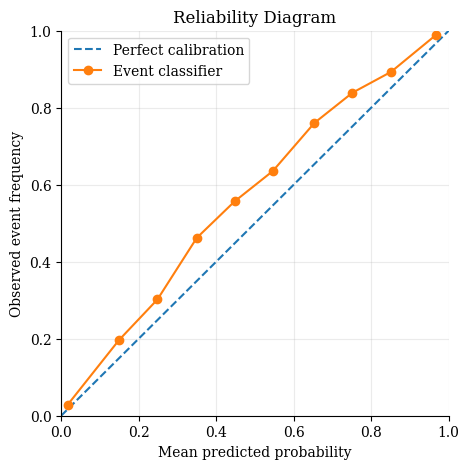


========== EVENT CLASSIFIER CALIBRATION ==========
ECE: 0.0235
Number of test samples: 49081


In [32]:
# Exercise 5: reliability diagram and ECE for the event classifier

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

if "p_ev" in dir():

    # Convert labels and probabilities to numpy arrays
    y_true = np.asarray(yb_te).astype(int)
    p_pred = np.asarray(p_ev, dtype=float)

    # Reliability curve
    frac_pos, mean_pred = calibration_curve(
        y_true,
        p_pred,
        n_bins=10,
        strategy="uniform"
    )

    # ---------- ECE ----------
    # 10 probability bins: [0,.1), [.1,.2), ..., [.9,1]
    bin_ids = np.minimum((p_pred * 10).astype(int), 9)

    ece = 0.0

    for k in range(10):
        mask = (bin_ids == k)

        if mask.sum() == 0:
            continue

        bin_weight = mask.mean()
        actual_rate = y_true[mask].mean()
        predicted_rate = p_pred[mask].mean()

        ece += bin_weight * abs(actual_rate - predicted_rate)

    # ---------- Reliability diagram ----------
    plt.figure(figsize=(5, 5))

    # Perfect calibration line
    plt.plot(
        [0, 1],
        [0, 1],
        "--",
        label="Perfect calibration"
    )

    # Event classifier calibration
    plt.plot(
        mean_pred,
        frac_pos,
        marker="o",
        label="Event classifier"
    )

    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed event frequency")
    plt.title("Reliability Diagram")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.25)

    plt.show()

    print("\n========== EVENT CLASSIFIER CALIBRATION ==========")
    print("ECE:", round(float(ece), 4))
    print("Number of test samples:", len(y_true))

else:
    print("p_ev not found. Run the event-classifier cell first.")

In [31]:
# Exercise 6: cost-sensitive threshold
# Missed event (FN) costs 5x a false alarm (FP)

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier

# =========================================================
# 1. Create event classifier if p_ev does not exist
# =========================================================

if "p_ev" not in dir():

    print("p_ev not found -> creating event classifier first...")

    # High-demand threshold = 90th percentile of training target
    event_q = EVENT_QUANTILE if "EVENT_QUANTILE" in dir() else 0.90
    event_threshold = train[Y].quantile(event_q)

    # Binary event labels
    yb_tr = (train[Y].values > event_threshold).astype(int)
    yb_te = (test[Y].values > event_threshold).astype(int)

    # Event classifier
    event_model = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        random_state=0,
        verbose=-1
    )

    print("Training event classifier...")

    event_model.fit(
        train[best_cols],
        yb_tr
    )

    # Probability that each test row is a high-demand event
    p_ev = event_model.predict_proba(
        test[best_cols]
    )[:, 1]

    print("Event classifier ready.")
    print("Event threshold:", round(event_threshold, 4), "kWh")
    print("Number of true events:", int(yb_te.sum()))

else:
    print("Using existing p_ev.")

    # Make sure yb_te exists
    if "yb_te" not in dir():
        event_q = EVENT_QUANTILE if "EVENT_QUANTILE" in dir() else 0.90
        event_threshold = train[Y].quantile(event_q)
        yb_te = (test[Y].values > event_threshold).astype(int)


# =========================================================
# 2. Cost-sensitive threshold search
# FN cost = 5
# FP cost = 1
# =========================================================

rows = []

for t in np.linspace(0.01, 0.99, 99):

    pred_event = (p_ev >= t).astype(int)

    TP = ((pred_event == 1) & (yb_te == 1)).sum()
    FP = ((pred_event == 1) & (yb_te == 0)).sum()
    FN = ((pred_event == 0) & (yb_te == 1)).sum()
    TN = ((pred_event == 0) & (yb_te == 0)).sum()

    cost = 5 * FN + FP

    precision = TP / max(TP + FP, 1)
    recall = TP / max(TP + FN, 1)
    f1 = (
        2 * precision * recall / max(precision + recall, 1e-12)
    )

    rows.append([
        t,
        cost,
        TP,
        FP,
        FN,
        TN,
        precision,
        recall,
        f1
    ])


cost_table = pd.DataFrame(
    rows,
    columns=[
        "threshold",
        "cost",
        "TP",
        "FP",
        "FN",
        "TN",
        "precision",
        "recall",
        "F1"
    ]
)

# Best threshold = minimum total cost
best_row = cost_table.loc[cost_table["cost"].idxmin()]

print("\n========== COST-SENSITIVE RESULT ==========")
print("Best threshold :", round(best_row["threshold"], 2))
print("Minimum cost   :", int(best_row["cost"]))
print()
print("TP :", int(best_row["TP"]))
print("FP :", int(best_row["FP"]))
print("FN :", int(best_row["FN"]))
print("TN :", int(best_row["TN"]))
print()
print("Precision :", round(best_row["precision"], 4))
print("Recall    :", round(best_row["recall"], 4))
print("F1        :", round(best_row["F1"], 4))

Using existing p_ev.

========== COST-SENSITIVE RESULT ==========
Best threshold : 0.14
Minimum cost   : 9199

TP : 7713
FP : 3394
FN : 1161
TN : 36813

Precision : 0.6944
Recall    : 0.8692
F1        : 0.772


### Tự đánh giá Notebook_D (điền trước khi gửi giảng viên)

| Tiêu chí | Tự chấm (0-2) | Bằng chứng |
|---|---|---|
| Sáu họ mô hình, năm seed, mọi tầm | | table_rq2_summary.csv |
| Thắng naive mùa có kiểm định | | MASE, Wilcoxon |
| Tổng quát hoá theo thời gian và đơn vị | | table_rq2_rolling.csv, table_rq2_unseen_units.csv |
| Khoảng tin cậy và cảnh báo | | table_rq3_coverage_by_unit.csv, table_rq3_warning.csv |
| Đổi chế độ và ablation | | table_rq3_regime.csv, table_rq3_ablation.csv |
| SHAP nhất quán với ablation | | table_shap.csv |
| Bài tập mở rộng | | exercises_D.md |
| AI Audit Log | | ai_audit_log.csv |

## Lỗi thường gặp và cách sửa (mô hình)

| Lỗi | Nguyên nhân | Cách sửa |
|---|---|---|
| `KeyError: 'ts'` | tên cột trong file khác CONFIG | in `df.columns`, sửa `TIME_COL` |
| Rò rỉ tương lai (điểm quá tốt) | dùng `shift(-k)` hoặc trung bình cả chuỗi khi tạo đặc trưng | chỉ dùng `LAG` và cửa sổ `PRECEDING`; kiểm tra `feat.ts` của đặc trưng luôn nhỏ hơn mục tiêu |
| Trùng dòng theo đơn vị và thời gian | nguồn có hai bản ghi cùng thời điểm | `drop_duplicates([UNIT_COL, TIME_COL])` rồi ghi vào nhật ký làm sạch |
| Lưới thời gian thiếu bước | không `resample(FREQ)` | resample và đếm bước thiếu theo đơn vị |
| Ghép nguồn phụ mất nửa dòng | lệch múi giờ hoặc lệch tần suất | đưa cả hai về UTC hoặc giờ địa phương thống nhất, dùng `merge_asof` với `tolerance` |
| DuckDB `Binder Error` | tên cột là từ khoá (`do`, `at`, `year`) hoặc trùng tên bảng | đổi tên cột, dùng dấu ngoặc kép |
| `MemoryError` | nạp toàn bộ file lớn bằng pandas | dùng `duckdb.read_csv_auto` và lọc sớm |
| Chronos không cài được | thiếu `pip install chronos-forecasting` | bỏ qua ô mô hình nền, ghi vào hạn chế |
| `ValueError: Input contains NaN` | đặc trưng trễ thiếu ở đầu chuỗi | `dropna` như Bước 4a; không điền 0 |
| Điểm quá tốt (MASE gần 0) | rò rỉ: đặc trưng chứa tương lai hoặc mục tiêu | kiểm tra ô rò rỉ ở Notebook_C, bỏ `y_diff1` nếu tính sai chiều |
| Chronos chạy quá lâu | ngữ cảnh dài, nhiều đơn vị | giảm `CTX`, số đơn vị, hoặc chạy Colab GPU |

## Checklist Notebook_D trước khi viết bài

- [ ] Bảng RQ2 summary có trung bình và độ lệch chuẩn qua 5 seed; MASE của mô hình tốt nhất dưới 1
- [ ] Hình so sánh mô hình có số in đậm trên cột, không thanh sai số; hình theo tầm
- [ ] Bảng rolling origin và bảng unseen units (RQ2 sâu)
- [ ] Bao phủ conformal theo đơn vị; cảnh báo sự kiện với recall và precision; đổi chế độ; ablation nguồn phụ (RQ3)
- [ ] SHAP top-5 và ổn định seed nhất quán với ablation
- [ ] Bảng chẩn đoán điền đủ số; test cases qua
- [ ] AI Audit Log có ít nhất 6 mục cho tuần 2 và 3, ít nhất một mục `hallucination=True`

## Mẫu viết phần Results và Discussion (điền số từ các bảng)

**RQ2.** On horizon {H0}, {best} achieves MAE {mae} (MASE {mase}), {gain}% below the seasonal naive baseline and {p} in a paired Wilcoxon test against {runner} (Table RQ2). The ranking holds across {k} rolling origins (spread {spread}) and the model keeps {pct}% of its accuracy on units never seen in training (Table unseen units). Zero-shot foundation models reach MAE {fm}, {comparison} the covariate-aware global model.

**RQ3.** Split conformal intervals cover {cov}% of test values with half-width {w}; {n} units fall below 0.85 coverage. A warning at {factor} times the event threshold reaches recall {rec} and precision {prec}; the conformal classifier holds the false-alarm rate at {fa}% with recall {rec2}. Removing the secondary source raises MAE by {abl}%, and monthly retraining reduces the post-shift error from {e1} to {e2}.

**Discussion.** Two caveats bound the claims: {caveat 1 from the diagnosis table} and {caveat 2}. Practically, {who} can use the {artifact} to {decision}, and the next step is {next}.